# BERTopic 토픽 모델링 실습: 국민청원으로 답변 순서 정하기

2018년 청와대 국민청원 1만 건으로 토픽 모델링을 하고, 그 결과로 답변 인력을 먼저 배정할 주제의 우선순위 표를 만듭니다.

**핵심 질문**

> 국민청원 게시판의 답변 담당 부서가 다음 분기에 답변 인력을 먼저 배정할 주제는 무엇일까요?

답변 담당 부서가 이 분석을 의뢰했다고 가정합니다. 답은 「13. 결과 정리」에 있습니다.

**만들 결과물**

| 결과물 | 내용 |
|---|---|
| 토픽 표 | 토픽 이름, 청원 수, 비율, 동의 100 이상 비율 |
| 월별 추이 | 토픽마다 달별 비율 |
| 우선순위 표 | 비율 · 동의 수 · 최근 3개월 증가로 정한 순서 |
| 한계 | 이 결과를 쓸 때 주의할 점 3가지 |

**진행 순서(약 140분)**

1. 문제 정의
2. 데이터 불러오기와 정제
3. 임베딩 미리 계산하기
4. 기본 설정으로 먼저 적합하기
5. BERTopic 안의 UMAP 과 HDBSCAN
6. 최소 군집 크기 고르기
7. 토픽 단어 다듬기
8. 토픽 이름 짓기
9. 비슷한 토픽 합치기
10. 이상치 다루기
11. 결과 검증
12. 먼저 맡을 주제 고르기
13. 결과 정리
14. 새 청원에 토픽 배정하기
15. 직접 해 보기

**실행 전에 할 일**

- Colab 메뉴 「런타임 → 런타임 유형 변경」에서 **T4 GPU** 를 고릅니다. GPU 가 없어도 끝까지 실행되지만 임베딩 계산이 10분 넘게 걸립니다.
- 셀은 위에서부터 차례로 실행합니다. Colab T4 에서 전체 실행은 약 8분 걸립니다.

**본문의 수와 출력이 다를 때**

본문의 수는 노트북을 만들 때 맥에서 실행한 값입니다. Colab 에서는 토픽 수 · 비율 · 상위 단어의 순서가 조금 다를 수 있습니다. 본문과 출력이 다르면 출력의 수가 맞습니다.

## 1. 문제 정의

토픽 모델링을 시작하기 전에 세 가지를 먼저 정합니다. 결과를 받는 사람, 그 사람이 내릴 결정, 결정에 필요한 단위입니다.

| 정할 것 | 국민청원 분석 |
|---|---|
| 결과를 받는 사람 | 국민청원 게시판의 답변 담당 부서 |
| 내릴 결정 | 다음 분기에 답변 인력을 먼저 배정할 주제 |
| 필요한 단위 | 부서 안의 담당자가 나눠 맡을 수 있는 주제 20～30개, 달별 비율 |

토픽을 몇 개로 나눌지, 어떤 토픽을 합칠지는 모두 「담당자가 나눠 맡을 수 있는가」로 정합니다.

토픽 모델링만으로 핵심 질문에 모두 답할 수는 없습니다.

| 토픽 모델링으로 답할 수 있는 것 | 답할 수 없는 것 |
|---|---|
| 청원이 어떤 주제로 나뉘는지 | 청원의 주장이 옳은지 |
| 주제마다 청원이 몇 %인지 | 어느 주제가 정책으로 더 중요한지 |
| 달마다 주제 비율이 어떻게 바뀌는지 | 다음 분기에 어떤 사건이 생길지 |
| 기존 청원 분류로는 보이지 않는 주제 | 청원 한 건에 주제가 2개일 때 각 주제의 비중 |

공개된 기업 사례에서도 모델이 찾은 토픽 수와 업무에서 쓰는 주제 수가 달랐습니다. 세르비아 통신사 Telekom Srbija 는 고객 이메일 약 9만 건에서 토픽 72개를 찾았습니다. 그리고 고객센터와 함께 이를 업무 분류 12개로 다시 나눴습니다. 「9. 비슷한 토픽 합치기」에서도 모델이 찾은 토픽을 담당자가 맡을 단위로 합칩니다.

### 라이브러리 설치

`bertopic` 을 설치하면 UMAP · HDBSCAN · sentence-transformers 도 함께 설치됩니다. `bertopic` 은 0.17.4 로 버전을 고정합니다. 버전이 바뀌면 함수의 기본값이 달라질 수 있기 때문입니다.

`kiwipiepy` 는 한국어 형태소 분석기 Kiwi 입니다. `koreanize-matplotlib` 는 그림의 한글 글꼴을 맞춰 줍니다.

In [ ]:
!pip -q install bertopic==0.17.4 kiwipiepy koreanize-matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 10.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 86.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 87.0 MB/s eta 0:00:00


In [ ]:
# Colab T4 에서 약 50초 걸립니다
import os, re, time
os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # 맥(ARM)과 Colab(x86)에서 Kiwi 결과를 같게
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 그림의 한글 글꼴
import torch
import bertopic
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from kiwipiepy import Kiwi
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import adjusted_rand_score

pd.set_option("display.max_colwidth", 90)
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("장치:", device, "| bertopic", bertopic.__version__)

장치: cuda | bertopic 0.17.4


## 2. 데이터 불러오기와 정제

### 데이터 카드

| 항목 | 내용 |
|---|---|
| 이름 | 청와대 국민청원 2017～2019 |
| 출처 | Hugging Face [heegyu/korean-petitions](https://huggingface.co/datasets/heegyu/korean-petitions). 원 수집본은 GitHub [lovit/petitions_archive](https://github.com/lovit/petitions_archive) |
| 이용 조건 | 원 수집본에는 라이선스 표기가 없습니다. Hugging Face 카드의 MIT 는 데이터를 등록한 계정이 표기한 것입니다. 그래서 파일을 다시 배포하지 않고 Hugging Face 에서 바로 읽습니다 |
| 청원 한 건 | 제목 · 본문 · 청원 분류(17개) · 청원 시작일 · 동의 수 |
| 분석 범위 | 2018년 1～12월에 시작한 청원 |
| 한계 | 동의 수는 수집 시점의 값입니다. 삭제된 청원이 빠졌는지는 확인하지 못했습니다 |

### 필요한 열과 달만 읽기

원본 파일은 2017～2019년 청원 약 44만 건, 약 330MB 입니다. Hugging Face 는 이 데이터를 parquet 파일 2개로 바꿔 제공합니다. parquet 는 열마다 따로 저장하는 파일 형식이라 필요한 열만 읽을 수 있습니다.

이 파일은 청원 시작일 순으로 저장돼 있어서, `filters` 로 2018년만 지정하면 다른 해의 행은 내려받지 않습니다. Colab T4 에서 읽는 데 약 15초 걸립니다.

In [ ]:
BASE = "https://huggingface.co/api/datasets/heegyu/korean-petitions/parquet/default/train/"
COLS = ["title", "content", "category", "begin", "num_agree"]
IN_2018 = [("begin", ">=", pd.Timestamp("2018-01-01")), ("begin", "<", pd.Timestamp("2019-01-01"))]

t0 = time.time()
raw = pd.concat([pd.read_parquet(BASE + f"{i}.parquet", columns=COLS, filters=IN_2018)
                 for i in (0, 1)], ignore_index=True)
print(f"2018년 청원 {len(raw):,}건, {time.time() - t0:.0f}초")

2018년 청원 298,459건, 14초


### 원문 마스킹

청원 원문에는 청원인이 스스로 밝힌 이름이나 연락처가 들어 있기도 합니다. 분석 대상은 개인이 아니라 주제이므로, 원문을 화면에 보일 때는 늘 `mask` 함수를 거칩니다.

**마스킹(masking)** 은 개인을 알아볼 수 있는 정보를 같은 길이의 「○」로 바꾸는 처리입니다. `mask` 는 자기소개 속 이름, 전화번호, 이메일, 주민등록번호 꼴의 숫자를 ○로 바꾸고, 글을 앞 80자까지만 보여 줍니다.

정규식 몇 개로 만든 간단한 예라서 모든 개인정보를 찾지는 못합니다. 원문을 다른 사람에게 보여 줄 때는 데이터에 맞게 패턴을 추가합니다.

In [ ]:
# 개인정보 마스킹 패턴: 자기소개 속 이름 · 전화번호 · 이메일 · 주민등록번호 꼴 숫자
PII_PATTERNS = [
    r"(?<=저는 )[가-힣]{2,4}?(?=입니다)",                  # 「저는 홍길동입니다」
    r"[가-힣]{2,4}?(?=(?:이)?라고 ?합니다)",                # 「홍길동이라고 합니다」
    r"0\d{1,2}[-. ]?\d{3,4}[-. ]?\d{4}",                # 전화번호(010-1234-5678, 02-123-4567)
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",    # 이메일
    r"\d{6}[- ]?[1-4]\d{6}",                            # 주민등록번호 꼴
]
PII_RE = re.compile("|".join(PII_PATTERNS))

def mask(text, n=80):
    text = PII_RE.sub(lambda m: "○" * len(m.group()), str(text))
    return text if len(text) <= n else text[:n] + "…"

print(mask("예로 만든 문장: 저는 홍길동이라고 합니다. 연락처는 010-1234-5678 입니다"))
raw.sample(3, random_state=1).assign(title=lambda d: d["title"].map(mask), content=lambda d: d["content"].map(mask))

예로 만든 문장: 저는 ○○○이라고 합니다. 연락처는 ○○○○○○○○○○○○○ 입니다


,title,content,category,begin,num_agree
229924,재정지원제한대학 학생들에게도 국가장학금은 지급되어야 합니다.,○ 교육부는 대학기본역량진단시 재정지원제한대학으로 선정된 학교에 재정지원제한뿐만 아니라 해당 학교 학생들에게도 학자금 대출을 제한하고 국가장학금…,육아/교육,2018-10-01,514
45862,존경하는 문재인 대통령님 백혈병(혈액암) 환자들좀 구원해 주십시오.간청 드립니다.,왜.백혈병 환자들은 장애인 혜택을 못받는지요. 전 이제 40에 중소기업에 다니는 평범한 직장인 입니다. 몇해전 저희 형수가 백혈병 진단을 받아 …,보건복지,2018-02-18,3
197136,삼성전자 갤럭시 노트 8 발열문제,"삼성전자 갤럭시 노트 8제품 발열 문제 구매시점 : 2017년 11월, 제품보증기간 이내 - 삼성 AS센터 : 삼성 수색 AS 센터 - 2018…",기타,2018-08-22,2


### 정제

정제는 두 가지만 합니다.

- **본문이 빈 청원 제외**: 제목만 있는 청원은 주제를 알기 어렵습니다.
- **중복 청원 제외**: 제목과 본문이 똑같은 청원이 여러 번 등록된 경우가 있습니다. 제외하지 않으면 그 주제의 건수가 늘고, 똑같은 글끼리 작은 군집이 생깁니다.

토픽 모델링에 쓰는 글은 「제목 + 본문 앞부분」을 150자에서 자른 것입니다. 300자로 자르면 토픽은 거의 같고 임베딩 시간만 2배가 됩니다. 제목만 쓰면 실행에 따라 토픽이 2개로 줄어드는 일이 있습니다.

In [ ]:
steps = {"2018년 청원": len(raw)}
df = raw[raw["content"].fillna("").str.strip() != ""]
steps["본문이 빈 청원 제외"] = len(df)
df = df.drop_duplicates(["title", "content"]).reset_index(drop=True)
steps["중복 청원 제외"] = len(df)

MAX_LEN = 150
df["doc"] = ((df["title"].fillna("") + " " + df["content"])
             .str.replace(r"\s+", " ", regex=True).str.strip().str.slice(0, MAX_LEN))
pd.Series(steps, name="청원 수").to_frame()

,청원 수
2018년 청원,298459
본문이 빈 청원 제외,298393
중복 청원 제외,293235


본문이 빈 청원은 66건뿐이고, 중복 청원은 약 5,000건(약 2%)입니다. 정제한 뒤에도 청원이 약 29만 건 남습니다.

### 학습용 표본과 새 청원 나누기

29만 건을 모두 쓰면 Colab T4 에서도 임베딩 계산에만 약 17분 걸립니다. 주제별 비율을 % 단위로 비교하기에는 1만 건이면 충분합니다. 남은 청원에서 1만 건을 무작위로 추출해 토픽 모델을 학습합니다.

나머지 청원에서 500건을 따로 추출합니다. 이 500건은 「14. 새 청원에 토픽 배정하기」에서 학습 뒤에 접수된 새 청원처럼 씁니다.

In [ ]:
N_SAMPLE = 10_000
sample = df.sample(n=N_SAMPLE, random_state=0)
new = df.drop(sample.index).sample(n=500, random_state=1).reset_index(drop=True)
sample = sample.reset_index(drop=True)

print("학습 표본:", len(sample), "| 새 청원:", len(new))
print(f"동의 100 이상인 청원: {(sample['num_agree'] >= 100).mean():.1%}")
sample["begin"].dt.month.value_counts().sort_index().rename("청원 수").to_frame().T

학습 표본: 10000 | 새 청원: 500
동의 100 이상인 청원: 5.6%


begin,1,2,3,4,5,6,7,8,9,10,11,12
청원 수,977,816,744,783,848,882,848,988,837,860,732,685


- 동의 수 100 이상인 청원은 약 6%입니다. 대부분의 청원은 동의가 적습니다.
- 달마다 표본이 약 700～1,000건이라 달별 비율을 계산할 수 있습니다.

## 3. 임베딩 미리 계산하기

**임베딩(embedding)** 은 글 하나를 수 여러 개로 된 벡터로 바꾼 것입니다. **차원** 은 벡터를 이루는 수의 개수입니다. KURE-v1 의 임베딩은 수 1,024개로 된 1,024차원 벡터입니다. 뜻이 가까운 청원일수록 두 벡터의 코사인 유사도가 큽니다.

BERTopic 은 설정을 바꿔 가며 여러 번 적합하는 것이 보통입니다. 그런데 임베딩 계산이 전체 시간의 대부분을 차지합니다. 임베딩은 한 번만 계산해 `.npy` 파일로 저장하고, 다음부터는 파일을 불러옵니다.

- 모델은 자연어 수업에서 쓴 한국어 임베딩 모델 KURE-v1 입니다.
- GPU 에서는 `half()` 로 16비트 실수 계산을 써서 시간을 줄입니다.
- 파일 이름에 표본 크기와 글 길이가 있습니다. 표본이나 글 길이를 바꾸면 이름이 달라져 새로 계산합니다.

**런타임이 끊겼을 때**: Colab 은 런타임이 끝나면 파일이 지워집니다. 미리 `.npy` 파일을 내려받아 두었다면, Colab 왼쪽의 파일 목록으로 드래그해 업로드한 뒤 처음 셀부터 다시 실행합니다. 이 셀은 파일을 찾아 인코딩을 건너뜁니다.

In [ ]:
# Colab T4 에서 약 1분 30초 걸립니다(모델 2.3GB 내려받기 포함)
EMB_PATH = f"emb_kure_n{len(sample)}_l{MAX_LEN}.npy"

emb_model = SentenceTransformer("nlpai-lab/KURE-v1", device=device)
emb_model.max_seq_length = 256
if device == "cuda":
    emb_model.half()  # 16비트 실수로 계산

if os.path.exists(EMB_PATH):
    emb = np.load(EMB_PATH)
    print("저장된 임베딩을 불러왔습니다:", EMB_PATH, emb.shape)
else:
    t0 = time.time()
    emb = emb_model.encode(sample["doc"].tolist(), batch_size=64,
                           normalize_embeddings=True, show_progress_bar=True)
    emb = np.asarray(emb, dtype=np.float32)
    np.save(EMB_PATH, emb)
    print(f"인코딩 {time.time() - t0:.0f}초, 모양 {emb.shape}, 저장 {EMB_PATH}")

emb_new = np.asarray(emb_model.encode(new["doc"].tolist(), normalize_embeddings=True), dtype=np.float32)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/220 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.3k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/807 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

인코딩 37초, 모양 (10000, 1024), 저장 emb_kure_n10000_l150.npy


청원 1만 건이 각각 1,024차원 벡터가 되었습니다(출력의 `(10000, 1024)`). 인코딩만 따지면 Colab T4 에서 약 30초, Apple M1 맥에서는 약 3분 걸립니다.

## 4. 기본 설정으로 먼저 적합하기

**토픽(topic)** 은 같은 주제를 다룬 청원들의 군집 하나입니다. BERTopic 은 4단계로 토픽을 찾습니다.

1. 임베딩: 청원을 1,024차원 벡터로 바꿉니다.
2. UMAP: 벡터를 5차원으로 줄입니다.
3. HDBSCAN: 5차원 공간에서 청원이 밀집된 영역을 군집으로 찾고, 군집 하나를 토픽 하나로 씁니다. 어느 군집에도 속하지 않은 청원은 이상치(−1)입니다.
4. c-TF-IDF: 토픽마다 그 토픽의 청원을 하나로 이은 글에서 단어 빈도를 계산합니다. 그리고 그 토픽에 특히 많이 나오는 단어를 골라 상위 단어로 씁니다.

먼저 모든 설정을 기본값 그대로 써서 적합해 봅니다. 기본값에서 생기는 문제마다 바꿀 설정이 하나씩 있습니다. 임베딩은 위에서 계산한 것을 `embeddings=` 로 전달합니다.

In [ ]:
# Colab T4 에서 약 40초 걸립니다
docs = sample["doc"].tolist()

t0 = time.time()
base_model = BERTopic()  # 모든 설정이 기본값
base_topics, _ = base_model.fit_transform(docs, embeddings=emb)
n_base = len(set(base_topics)) - 1
print(f"토픽 {n_base}개 | 이상치 {np.mean(np.array(base_topics) == -1):.1%} | {time.time() - t0:.0f}초")
base_model.get_topic_info().head(6)[["Topic", "Count", "Name"]]

토픽 134개 | 이상치 29.6% | 36초


,Topic,Count,Name
0,-1,2962,-1_bmw_korea_31_36
1,0,600,0_lh_82_913_85
2,1,292,1_164281_120_150_by
3,2,276,2_2030_it_300_id
4,3,272,3_is_71_43_500
5,4,230,4_182_319441_ip_httpswww1presidentgokrpetitions444958


**시드(seed)** 는 난수를 만드는 시작값입니다. 같은 시드를 쓰면 난수가 같게 나와 결과를 다시 만들 수 있습니다.

결과에 문제가 세 가지 있습니다.

| 문제 | 원인 | 고치는 방법 |
|---|---|---|
| 토픽 이름에 한글이 없고 영문 · 숫자만 있음 | `language` 기본값 `"english"` | `language="multilingual"` |
| 토픽이 100개가 넘음 | 최소 군집 크기 기본값 10 | 「6. 최소 군집 크기 고르기」 |
| 실행할 때마다 결과가 달라짐 | UMAP 의 시드가 정해져 있지 않음 | `UMAP(random_state=0)` |

같은 셀을 여러 번 실행하면 토픽이 134～143개처럼 매번 달라집니다.

### 한글이 사라지는 이유

`language="english"` 이면 BERTopic 은 c-TF-IDF 를 계산하기 전에 글자 일부를 지웁니다. 영문 · 숫자 · 공백이 아닌 글자는 모두 지워집니다. 같은 처리를 청원 하나에 적용해 봅니다.

In [ ]:
example = docs[45]
print("원문      :", mask(example, 70))
print("처리한 뒤 :", re.sub(r"[^A-Za-z0-9 ]+", "", example).split())

원문      : 부동산집값을 낮출려면 LH아파트를 국가에서 매입을 하여 현재 살고 있는 국민들의 보금자리 집값을 낮출려면 우선 LH아파트에 살…
처리한 뒤 : ['LH', 'LH']


한글이 모두 지워지고 영문 · 숫자만 남습니다. 그래서 토픽 이름이 영문 약자와 숫자로만 이루어집니다. 한글을 쓰는 데이터는 `language="multilingual"` 로 바꿉니다. 아래에서 단어를 나누는 방법을 따로 지정하더라도 이 처리는 그대로 적용되므로, `language` 는 늘 바꿉니다.

### Kiwi 로 명사 추출

`language` 를 바꿔도 기본 설정은 띄어쓰기로 단어를 나눕니다. 그러면 「부동산을」 · 「부동산이」가 다른 단어가 됩니다. Kiwi 로 청원마다 일반 명사(NNG) · 고유 명사(NNP)만 고르면 두 단어가 「부동산」 하나가 됩니다.

임베딩은 원문으로 계산하고, 명사는 토픽 단어를 고를 때만 씁니다. 임베딩 모델은 조사 · 어미까지 포함한 문장으로 학습했기 때문에, 원문을 입력해야 뜻을 온전히 반영합니다. BERTopic 문서도 불용어 제거 같은 전처리는 임베딩 전이 아니라 단어 빈도를 계산할 때 하라고 권합니다.

In [ ]:
# Colab T4 에서 약 40초 걸립니다
kiwi = Kiwi()  # 「Quantization is not supported」 안내가 나와도 그대로 진행합니다

def nouns(texts):
    # 청원마다 일반 명사(NNG) · 고유 명사(NNP)만 공백으로 이은 문자열
    return [" ".join(t.form for t in toks if t.tag in ("NNG", "NNP")) for toks in kiwi.tokenize(texts)]

t0 = time.time()
sample["nouns"] = nouns(sample["doc"].tolist())
new["nouns"] = nouns(new["doc"].tolist())
print(f"Kiwi 명사 추출 {time.time() - t0:.0f}초")
sample[["doc", "nouns"]].head(3).map(mask)

Kiwi 명사 추출 37초


,doc,nouns
0,"대북특사에 홍준표, 김성태씨 추천합니다. 올림픽때 내려온 김여정이 가져온 김정은의 방북초청에 응할 대북특사를 선정하고 있다고 알고 있습니다. 지…",대북 특사 홍준표 김성태 추천 올림픽 때 김 여정 김정은 방북 초청 대북 특사 선정 거론 생각 홍준표 김성태 대북 특사 강력 추천 사람
1,"춘천~삼척 고속도로를 만들어주세요 춘천과삼척,울진,영덕을 가는시간이 너무 오래걸림니다. 춘천에서 삼척까지 3시간이 걸림니다.문재인 대통령님 춘천…",춘천 삼척 고속 도로 춘천과삼척 울진 영덕 시간 춘천 삼척 문재인 대통령 춘천 삼척 고속 도로 감사
2,디딤씨앗통장(중도해지 할수 잇게 안녕하세요 저는 춘천에 사는 2장애 아이를 키우는 엄마 입니다 하지만 저는 디딤씨앗이라는 통장을 올해 알어습니다…,디딤씨앗통장 중도 해지 안녕 춘천 장애 아이 엄마 씨앗 통장 올해 근대 실제 가입 아빠 해지 은행 중도 해지 가능


오른쪽 `nouns` 에는 조사와 어미가 빠지고 명사만 남습니다. 「대북특사에」는 「대북 특사」가 됩니다.

**불용어(stop word)** 는 토픽 단어에서 뺄 단어입니다. 어느 토픽에나 나오는 「것 · 수 · 등」 같은 단어 18개와, 청원이라면 거의 모두 쓰는 「청원 · 국민 · 대통령 · 생각 · 부탁」 5개를 뺍니다. 불용어는 토픽 단어만 바꾸고 군집에는 영향이 없습니다.

`CountVectorizer` 는 **문서-단어 행렬** 을 만드는 scikit-learn 클래스입니다. 문서-단어 행렬은 문서마다 단어 빈도를 적은 표입니다. 명사는 이미 공백으로 이어져 있으므로 `tokenizer=str.split` 으로 공백만 기준으로 나눕니다.

In [ ]:
STOP_WORDS = ["것", "수", "등", "때", "거", "중", "년", "월", "일", "분", "번", "개", "명", "곳",
              "데", "점", "뭐", "좀", "청원", "국민", "대통령", "생각", "부탁"]
vectorizer = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                             stop_words=STOP_WORDS)
docs_nouns = sample["nouns"].tolist()

## 5. BERTopic 안의 UMAP 과 HDBSCAN

토픽 수와 이상치 비율은 대부분 UMAP 과 HDBSCAN 의 설정에서 정해집니다. 두 알고리즘이 하는 일과 주요 인자를 먼저 봅니다.

### UMAP: 차원 줄이기

**UMAP** 은 이웃 그래프를 만든 뒤, 저차원에서도 비슷한 이웃 관계가 되도록 위치를 반복해서 고치는 비선형 차원 축소 방법입니다. PCA 처럼 원래 변수에 가중치를 곱하고 더하는 선형 변환이 아닙니다. 이름은 Uniform Manifold Approximation and Projection 의 줄임말입니다.

BERTopic 은 HDBSCAN 으로 군집을 찾기 전에 차원을 줄입니다. 차원이 1,024개나 되면 청원 사이 거리가 모두 비슷해져서, 밀도가 높은 영역을 찾기 어렵기 때문입니다.

UMAP 은 가까운 청원끼리의 관계(국소 구조)는 잘 유지하지만, 멀리 떨어진 두 군집 사이의 거리는 원래 공간과 같다고 보장하지 않습니다. 줄인 공간에서 두 토픽이 멀다고 해서 두 주제가 그만큼 다른 것은 아닙니다.

| 인자 | 뜻 | 설정값 |
|---|---|---|
| `n_neighbors` | 이웃 그래프를 만들 때 쓰는 이웃 수. 작으면 좁은 범위의 이웃만, 크면 넓은 범위까지 반영 | 15 |
| `n_components` | 줄인 뒤의 차원 수 | 5 |
| `min_dist` | 줄인 공간에서 점 사이의 최소 거리. 0 이면 이웃끼리 밀집해 군집을 찾기 쉬움 | 0.0 |
| `metric` | 이웃을 찾을 때 쓰는 거리 | 코사인 |

### HDBSCAN: 밀도로 군집 찾기

**HDBSCAN** 은 밀도 기반 군집 방법입니다. 밀도를 반영한 거리로 모든 청원을 가장 짧게 잇고, 가장 긴 연결부터 끊어 군집이 나뉘는 과정을 나무로 기록합니다. 그다음 여러 거리 기준에서 계속 유지되는 군집을 고르고, 어느 군집에도 속하지 않은 청원은 이상치(−1)로 남깁니다.

이름의 H 는 Hierarchical(계층)이고, DBSCAN 은 아래 이름의 머리글자입니다. 군집 수는 미리 정하지 않습니다.

- Density-Based Spatial Clustering of Applications with Noise

| 인자 | 뜻 | 설정값 |
|---|---|---|
| `min_cluster_size` | 토픽으로 인정할 최소 청원 수 | 「6. 최소 군집 크기 고르기」에서 50 으로 정함 |
| `min_samples` | 밀도를 계산할 때 쓰는 이웃 수. 기본값은 `min_cluster_size` 와 같음. 클수록 이상치가 많음 | 기본값 |
| `cluster_selection_method` | 군집 선택 방식. 기본 `"eom"` 은 안정성이 큰 군집을, `"leaf"` 는 응축 트리 맨 아래의 작은 군집을 고름 | `"eom"` |

<details><summary>더 깊이: HDBSCAN 의 6단계</summary>

| 단계 | 하는 일 |
|---|---|
| 1. 핵심 거리 | 청원마다 `min_samples` 번째로 가까운 청원까지의 거리를 구합니다. 밀도가 높은 곳일수록 짧습니다 |
| 2. 상호 도달 거리 | 두 청원 사이의 거리를 실제 거리와 두 핵심 거리 가운데 가장 큰 값으로 바꿉니다 |
| 3. 최소 신장 트리 | 상호 도달 거리로, 연결 길이의 합이 가장 짧게 모든 청원을 잇습니다 |
| 4. 긴 연결부터 끊기 | 가장 긴 연결부터 하나씩 끊으며, 군집이 나뉘는 순서를 나무로 기록합니다 |
| 5. 응축 트리 | 나뉘어 나온 쪽이 `min_cluster_size` 보다 작으면, 군집이 아니라 떨어져 나간 청원으로 정리합니다 |
| 6. 안정성 선택 | 여러 거리 기준에서 계속 유지되는 군집을 고르고, 나머지 청원은 이상치(−1)로 남깁니다 |

**1～2단계를 작은 수로 계산하기**

**핵심 거리(core distance)** 는 한 청원에서 `min_samples` 번째로 가까운 청원까지의 거리입니다. `min_samples=2` 이고 청원 A 에서 가장 가까운 두 청원까지 거리가 0.1 과 0.3 이면, A 의 핵심 거리는 0.3 입니다.

**상호 도달 거리(mutual reachability distance)** 는 밀도를 반영한 두 청원 사이의 거리입니다. 두 청원 A · B 의 실제 거리, A 의 핵심 거리, B 의 핵심 거리 가운데 가장 큰 값입니다.

$$
\text{상호 도달 거리}(A, B) = \max\big(\text{실제 거리}(A, B),\ \text{핵심 거리}(A),\ \text{핵심 거리}(B)\big)
$$

- 실제 거리(A, B): 5차원 공간에서 두 청원 사이의 거리
- 핵심 거리(A), 핵심 거리(B): 두 청원 각각의 핵심 거리

| 경우 | 실제 거리 | 핵심 거리(A) | 핵심 거리(B) | 상호 도달 거리 |
|---|---:|---:|---:|---:|
| A · B 모두 밀도가 높은 곳 | 0.1 | 0.1 | 0.1 | 0.1 |
| A 만 밀도가 낮은 곳 | 0.1 | 0.3 | 0.1 | 0.3 |

두 경우 모두 실제 거리는 0.1 입니다. 그런데 A 가 밀도가 낮은 곳에 있으면 거리가 0.3 으로 늘어납니다. 밀도가 낮은 곳의 청원은 다른 청원과의 연결이 길어집니다.

**3～5단계를 작은 예로 보기**

청원 5건 A～E 를 상호 도달 거리로 이은 최소 신장 트리가 아래와 같다고 합니다. 숫자는 연결의 길이입니다.

```text
A --1-- B --2-- C
        |
        6
        |
        D --7-- E
```

- 가장 긴 7 을 끊으면 {A, B, C, D} 와 {E} 로 나뉩니다.
- 다음으로 긴 6 을 끊으면 {A, B, C} 와 {D} 로 나뉩니다.
- `min_cluster_size=3` 이면 {E} 와 {D} 는 군집이 아니라 떨어져 나간 청원입니다.

그래서 응축 트리에는 {A, B, C, D, E} 에서 {A, B, C} 로 이어지는 군집만 남습니다.

**6단계: 안정성 선택**

**안정성(stability)** 은 거리 기준을 바꿔도 같은 군집으로 유지되는 범위가 얼마나 넓은지 나타내는 값입니다. HDBSCAN 은 응축 트리의 군집마다 안정성을 계산합니다. 기본 방식 `"eom"` 은 안정성의 합이 가장 큰 군집들을 고릅니다.

</details>

### 인자를 하나씩 바꿔 보기

이 데이터로 인자를 하나씩 바꿔 봅니다. 세 가지를 비교합니다.

- 토픽 수
- 이상치 비율: 어느 토픽에도 속하지 않은 청원의 비율
- 가장 큰 토픽의 비율: 한 토픽이 청원 대부분을 차지하지 않는지

임베딩은 저장한 것을 다시 쓰고, UMAP 의 시드는 0 으로 고정합니다. `min_cluster_size` 는 「6. 최소 군집 크기 고르기」에서 고를 값인 50 을 씁니다.

In [ ]:
# Colab T4 에서 약 1분 30초 걸립니다(UMAP 을 3번 실행)
def summary(lab):
    sizes = pd.Series(lab[lab != -1]).value_counts()
    return {"토픽 수": len(sizes), "이상치 %": round((lab == -1).mean() * 100, 1),
            "가장 큰 토픽 %": round(sizes.iloc[0] / len(lab) * 100, 1)}

reduced_nn, rows = {}, []
for nn in (5, 15, 50):
    t0 = time.time()
    reduced_nn[nn] = UMAP(n_neighbors=nn, n_components=5, min_dist=0.0, metric="cosine",
                          random_state=0).fit_transform(emb)
    lab = HDBSCAN(min_cluster_size=50).fit(reduced_nn[nn]).labels_
    rows.append({"n_neighbors": nn, **summary(lab), "UMAP 초": round(time.time() - t0)})
pd.DataFrame(rows)

,n_neighbors,토픽 수,이상치 %,가장 큰 토픽 %,UMAP 초
0,5,31,23.3,13.5,15
1,15,30,31.5,6.4,23
2,50,33,35.6,6.4,42


`n_neighbors` 를 5 · 15 · 50 으로 바꿔도 토픽은 약 30～36개입니다. 이 데이터에서는 차이가 크지 않아 기본값 15 를 씁니다.

`n_neighbors` 가 5 일 때 토픽이 가장 많습니다. 이웃을 적게 반영하면 좁은 범위의 작은 밀집 영역이 군집으로 더 많이 남기 때문입니다.

HDBSCAN 의 인자만 바꿀 때는 UMAP 을 다시 실행하지 않습니다. 위에서 계산한 `n_neighbors=15` 결과를 다시 씁니다.

In [ ]:
rows = []
for ms in (None, 10, 1):
    lab = HDBSCAN(min_cluster_size=50, min_samples=ms).fit(reduced_nn[15]).labels_
    rows.append({"min_samples": "기본(50)" if ms is None else ms, **summary(lab)})
pd.DataFrame(rows)

,min_samples,토픽 수,이상치 %,가장 큰 토픽 %
0,기본(50),30,31.5,6.4
1,10,41,28.1,6.8
2,1,48,25.2,7.8


`min_samples` 를 낮추면 이상치가 줄어듭니다. 기본값에서 약 32%이던 이상치가 `min_samples=1` 에서는 약 22%가 됩니다. 대신 토픽도 약 30개에서 약 50개로 늘어납니다. 밀도를 계산할 때 쓰는 이웃 수가 줄어, 밀도가 조금 낮은 영역도 군집이 되기 때문입니다.

바꾸고 싶은 결과마다 먼저 조정할 인자가 다릅니다.

| 결과의 모습 | 먼저 조정할 인자 |
|---|---|
| 작은 토픽이 너무 많다 | `min_cluster_size` 를 크게 |
| 한 토픽이 청원 대부분을 차지한다 | `min_cluster_size` 를 작게, 또는 `min_samples` 를 작게 |
| 이상치가 너무 많다 | `min_samples` 를 작게(토픽도 늘어나므로 토픽 수를 다시 확인) |
| 같은 주제가 비슷한 토픽 여럿으로 나뉜다 | `n_neighbors` 를 크게(넓은 범위의 이웃을 반영) |

`min_samples` 는 기본값(50)을 씁니다. 낮추면 이상치는 줄지만 토픽이 50개 가까이로 늘어, 담당자가 나눠 맡을 단위(20～30개)를 초과하기 때문입니다.

두 알고리즘의 원리는 원 논문과 공식 문서에 그림과 함께 자세히 나와 있습니다.

- UMAP 원 논문: McInnes · Healy · Melville (2018), [UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction](https://arxiv.org/abs/1802.03426)
- UMAP 공식 문서: [How UMAP Works](https://umap-learn.readthedocs.io/en/latest/how_umap_works.html) · [Basic UMAP Parameters](https://umap-learn.readthedocs.io/en/latest/parameters.html)
- HDBSCAN 원 논문: Campello · Moulavi · Sander (2013), [Density-Based Clustering Based on Hierarchical Density Estimates](https://doi.org/10.1007/978-3-642-37456-2_14)
- HDBSCAN 구현 논문: McInnes · Healy · Astels (2017), [hdbscan: Hierarchical density based clustering](https://joss.theoj.org/papers/10.21105/joss.00205)
- HDBSCAN 공식 문서: [How HDBSCAN Works](https://hdbscan.readthedocs.io/en/latest/how_hdbscan_works.html) · [Parameter Selection for HDBSCAN](https://hdbscan.readthedocs.io/en/latest/parameter_selection.html)

## 6. 최소 군집 크기 고르기

**최소 군집 크기(`min_cluster_size`)** 는 HDBSCAN 이 토픽으로 인정할 최소 청원 수입니다. 값이 크면 토픽이 적고, 작으면 많습니다.

토픽 수를 줄이는 방법으로 `nr_topics` 도 있습니다. `nr_topics` 는 적합한 뒤 비슷한 토픽을 합쳐 개수를 줄이는 인자입니다. BERTopic 문서는 이렇게 나중에 줄이기보다 최소 군집 크기로 먼저 조절하라고 권합니다.

그런데 최소 군집 크기를 조금 키웠을 뿐인데 토픽이 갑자기 몇 개로 줄고, 한 토픽에 대부분이 몰릴 수 있습니다. 뉴스 기사 제목 데이터에서는 최소 군집 크기 30 일 때 토픽이 44개였지만, 60 일 때는 3개로 줄고 한 토픽에 기사의 77%가 모였습니다. 값마다 토픽 수 · 이상치 비율 · 가장 큰 토픽의 비율을 함께 봅니다.

### 시드별 결과 비교

`random_state` 로 UMAP 의 시드를 고정하면 같은 결과를 다시 만들 수 있습니다. 다만 결과를 다시 만들 수 있을 뿐, 결과가 안정적인지는 알 수 없습니다. 최소 군집 크기 30 · 50 · 100 을 시드 0 · 1 · 2 로 각각 실행해 비교합니다.

값 3개 × 시드 3개면 9번 적합해야 합니다. 시간이 가장 많이 드는 UMAP 은 시드마다 한 번만 실행합니다. 시드 0 은 위에서 계산한 결과를 다시 씁니다. HDBSCAN 만 다시 실행하면 한 번에 1초가 안 걸립니다.

In [ ]:
# Colab T4 에서 약 50초 걸립니다(UMAP 을 2번 실행)
umap_args = dict(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine")

reduced = {0: reduced_nn[15]}
for seed in (1, 2):
    t0 = time.time()
    reduced[seed] = UMAP(**umap_args, random_state=seed).fit_transform(emb)
    print(f"UMAP 시드 {seed}: {time.time() - t0:.0f}초")

UMAP 시드 1: 23초
UMAP 시드 2: 23초


In [ ]:
rows, labels_grid = [], {}
for mcs in (30, 50, 100):
    for seed in (0, 1, 2):
        lab = HDBSCAN(min_cluster_size=mcs, prediction_data=True).fit(reduced[seed]).labels_
        labels_grid[(mcs, seed)] = lab
        rows.append({"최소 군집 크기": mcs, "시드": seed, **summary(lab)})
grid = pd.DataFrame(rows)
grid

,최소 군집 크기,시드,토픽 수,이상치 %,가장 큰 토픽 %
0,30,0,54,33.4,6.1
1,30,1,58,32.2,6.8
2,30,2,56,33.0,6.5
3,50,0,30,31.5,6.4
4,50,1,30,30.4,6.5
5,50,2,30,29.7,7.1
6,100,0,22,35.2,6.7
7,100,1,21,36.2,6.8
8,100,2,21,36.1,6.9


최소 군집 크기는 50 으로 정합니다.

- 30 으로 하면 토픽이 55개를 넘어, 담당자가 나눠 맡기에 너무 잘게 나뉩니다.
- 100 으로 하면 토픽이 약 20개로 줄지만 이상치가 늘어납니다. 50 과 100 의 토픽 단어를 비교하면, 소방관 · 대한항공 일가 갑질처럼 작은 주제가 100 에서는 이상치로 바뀝니다.
- 50 으로 하면 토픽이 약 30개이고, 세 시드에서 토픽 수 차이가 1개 안팎입니다.

세 값 모두 가장 큰 토픽이 10%를 넘지 않습니다. 한 토픽이 청원 대부분을 차지하는 문제는 이 데이터에서는 생기지 않았습니다.

<details><summary>더 깊이: 최소 군집 크기별 결과 범위</summary>

| 최소 군집 크기 | 토픽 수 | 이상치 비율 | 가장 큰 토픽 |
|---:|---:|---:|---:|
| 30 | 55～57개 | 32～33% | 6～7% |
| 50 | 30～31개 | 31～34% | 6～7% |
| 100 | 20～21개 | 35～36% | 7～8% |

범위는 시드 0 · 1 · 2 로 실행한 결과의 최솟값～최댓값입니다.

</details>

### 두 배정을 비교하는 ARI

**ARI(Adjusted Rand Index, 조정 랜드 지수)** 는 두 배정이 얼마나 일치하는지 나타내는 값입니다. 아래에서 만들 모델의 배정이 위 표의 시드 0 · 최소 군집 크기 50 과 같은지 이 값으로 확인합니다.

ARI 는 청원을 두 건씩 짝지어, 한 배정에서 같은 토픽인 두 청원이 다른 배정에서도 같은 토픽인지 비교합니다. 그래서 토픽 번호가 달라도 비교할 수 있습니다. 완전히 같으면 1, 무작위로 나눈 수준이면 0 근처이고, 그보다 덜 일치하면 0 보다 작습니다.

청원 4건 A · B · C · D 로 계산해 봅니다. 4건이면 짝은 6개입니다.

| 배정 | A | B | C | D | 같은 토픽인 짝 |
|---|---:|---:|---:|---:|---|
| 배정 1 | 0 | 0 | 1 | 1 | A–B, C–D |
| 배정 2 | 5 | 5 | 2 | 2 | A–B, C–D |
| 배정 3 | 5 | 2 | 5 | 2 | A–C, B–D |

배정 1 과 배정 2 는 번호가 다르지만 같은 토픽인 짝이 같아 ARI 가 1 입니다. 배정 3 은 같은 토픽인 짝이 모두 달라 ARI 가 0 보다 작습니다.

In [ ]:
print("배정 1 대 배정 2:", adjusted_rand_score([0, 0, 1, 1], [5, 5, 2, 2]))
print("배정 1 대 배정 3:", adjusted_rand_score([0, 0, 1, 1], [5, 2, 5, 2]))

배정 1 대 배정 2: 1.0
배정 1 대 배정 3: -0.5


### 고른 설정으로 모델 만들기

정한 설정을 모두 지정해 모델을 만듭니다.

- `language="multilingual"`: 한글을 지우지 않습니다.
- `umap_model`: 시드 0 으로 고정한 UMAP 입니다.
- `hdbscan_model`: 최소 군집 크기 50 입니다. `prediction_data=True` 는 새 청원의 토픽을 정할 때 필요합니다.
- `vectorizer_model`: Kiwi 명사와 불용어를 쓰는 `CountVectorizer` 입니다.
- `embedding_model`: 「7. 토픽 단어 다듬기」에서 단어의 임베딩을 계산할 때 씁니다.

문서는 명사 문자열 `docs_nouns` 를 전달하고, 임베딩은 원문으로 계산한 `emb` 를 전달합니다. `fit_transform` 은 청원마다 토픽 번호(`topics`)와 소속 확률(`probs`)을 반환합니다. 소속 확률은 「8. 토픽 이름 짓기」에서 씁니다.

In [ ]:
# Colab T4 에서 약 30초 걸립니다
topic_model = BERTopic(
    language="multilingual",
    embedding_model=emb_model,
    umap_model=UMAP(**umap_args, random_state=0),
    hdbscan_model=HDBSCAN(min_cluster_size=50, metric="euclidean",
                          cluster_selection_method="eom", prediction_data=True),
    vectorizer_model=vectorizer,
)
t0 = time.time()
topics, probs = topic_model.fit_transform(docs_nouns, embeddings=emb)
sample["topic"], sample["prob"] = topics, probs
print(f"토픽 {len(set(topics)) - 1}개 | 이상치 {np.mean(np.array(topics) == -1):.1%} | {time.time() - t0:.0f}초")
print("위 표의 시드 0 · 최소 군집 크기 50 과 같은 배정인가(ARI):",
      round(adjusted_rand_score(topics, labels_grid[(50, 0)]), 3))

토픽 30개 | 이상치 31.5% | 24초
위 표의 시드 0 · 최소 군집 크기 50 과 같은 배정인가(ARI): 1.0


ARI 가 1.0 이므로 위 표의 시드 0 · 최소 군집 크기 50 과 청원 배정이 완전히 같습니다. 시드를 고정했기 때문에 같은 결과가 다시 나왔습니다.

이 모델의 토픽을 처음으로 확인합니다.

In [ ]:
topic_model.get_topic_info().head(10)[["Topic", "Count", "Name"]]

,Topic,Count,Name
0,-1,3148,-1_사람_나라_안녕_국가
1,0,635,0_부동산_주택_집값_아파트
2,1,625,1_사건_처벌_범죄_폭행
3,2,589,2_북한_문재인_올림픽_남북
4,3,559,3_임금_최저_정규직_인상
5,4,363,4_화폐_가상_거래소_폐쇄
6,5,362,5_택시_도로_차량_주차
7,6,292,6_난민_외국인_추방_불법
8,7,287,7_국회_의원_국회의원_선거
9,8,277,8_선수_축구_면제_연맹


- 맨 위의 Topic −1 은 토픽이 아니라 이상치 청원의 수입니다.
- Name 은 토픽 번호와 상위 단어 4개를 밑줄로 이은 자동 이름입니다.
- 「4. 기본 설정으로 먼저 적합하기」의 기본 모델과 달리 Name 에 한글 명사가 보입니다. 부동산 · 북한 · 범죄처럼 주제를 알 수 있는 단어입니다.

## 7. 토픽 단어 다듬기

상위 단어는 「8. 토픽 이름 짓기」에서 이름을 지을 때 읽는 첫 단서입니다. 그런데 지금 단어에는 둘로 쪼개진 고유명사와 뜻이 겹치는 단어가 있습니다. 청원의 토픽 배정은 바꾸지 않고 단어만 다시 고릅니다.

`update_topics` 는 배정은 바꾸지 않고 토픽 단어만 다시 계산하므로, 단어를 고칠 때마다 다시 적합할 필요가 없습니다.

### 쪼개진 고유명사 고치기

토픽 단어를 보면 Kiwi 가 고유명사를 두 단어로 나눈 곳이 있습니다. 정치인 수사 토픽에서 「드루킹」은 「드루 · 킹」으로 나뉩니다. 음주 운전 토픽에서 「윤창호」는 「윤 · 창호」로 나뉩니다. 윤창호는 음주 운전 처벌을 강화한 법(윤창호법)의 이름이 된 사람입니다.

두 이름을 Kiwi 의 사용자 사전에 등록하고 명사를 다시 추출합니다.

토픽 번호는 실행 환경에 따라 바뀔 수 있어서, 번호 대신 상위 단어로 토픽을 찾는 `find_topic` 함수를 먼저 만듭니다. 상위 단어 10개에 찾는 단어가 가장 많이, 가장 앞에 나오는 토픽을 고릅니다. 찾지 못하면 안내를 출력하고 `None` 을 반환합니다.

In [ ]:
def find_topic(*words, n=10):
    # 상위 단어 n개에 words 가 가장 많이, 가장 앞에 나오는 토픽 번호(없으면 안내 후 None)
    best, best_score = None, (0, 0)
    for t in sorted(set(topic_model.topics_) - {-1}):
        top = [w for w, _ in topic_model.get_topic(t)[:n]]
        hits = [top.index(w) for w in words if w in top]
        score = (len(hits), -min(hits)) if hits else (0, 0)
        if hits and score > best_score:
            best, best_score = t, score
    if best is None:
        print(f"이 실행에서는 「{' · '.join(words)}」 토픽이 나오지 않았습니다.")
        print("위 토픽 표에서 비슷한 토픽 번호를 골라, 이 셀의 find_topic(...) 을 그 번호로 바꿔 실행합니다.")
    return best

def top_words(t, aspect=None, n=6):
    pairs = topic_model.get_topic(t) if aspect is None else topic_model.topic_aspects_[aspect][t]
    return " · ".join(w for w, _ in pairs[:n])

t_probe = find_topic("특검", "이재명", "수사")
t_drunk = find_topic("음주", "운전")
for t in (t_probe, t_drunk):
    if t is not None:
        print(f"고치기 전 토픽 {t}:", top_words(t, n=10))

고치기 전 토픽 19: 특검 · 이재명 · 킹 · 드루 · 수사 · 도지사 · 김경수 · 조사 · 지사 · 사건
고치기 전 토픽 27: 음주 · 운전 · 처벌 · 강화 · 술 · 운전자 · 범죄 · 사고 · 살인 · 창호


In [ ]:
# Colab T4 에서 약 40초 걸립니다(명사를 다시 추출)
kiwi.add_user_word("드루킹", "NNP")
kiwi.add_user_word("윤창호", "NNP")
sample["nouns"] = nouns(sample["doc"].tolist())
new["nouns"] = nouns(new["doc"].tolist())
docs_nouns = sample["nouns"].tolist()

topic_model.update_topics(docs_nouns, vectorizer_model=vectorizer)
for t in (t_probe, t_drunk):
    if t is not None:
        print(f"고친 뒤   토픽 {t}:", top_words(t, n=10))

고친 뒤   토픽 19: 특검 · 이재명 · 드루킹 · 수사 · 도지사 · 김경수 · 조사 · 지사 · 사건 · 구속
고친 뒤   토픽 27: 음주 · 운전 · 처벌 · 강화 · 술 · 운전자 · 범죄 · 사고 · 살인 · 윤창호


고친 뒤에는 「드루킹」과 「윤창호」가 한 단어로 나옵니다. 「킹 · 드루」, 「윤 · 창호」처럼 뜻을 알 수 없는 조각은 사라집니다.

### 다른 방법으로 단어 고르기

c-TF-IDF 는 토픽에 자주 나오고 다른 토픽에는 덜 나오는 단어를 고릅니다. 이 밖에 BERTopic 이 제공하는 방법 두 가지를 함께 계산해 비교합니다.

**대표 청원** 은 BERTopic 이 토픽마다 고른, 상위 단어에 가장 잘 맞는 청원 몇 건입니다. 「8. 토픽 이름 짓기」에서 직접 읽습니다.

- **KeyBERTInspired 방법**: c-TF-IDF 상위 단어 후보 가운데 대표 청원의 임베딩과 가까운 단어를 고릅니다. 키워드 추출 라이브러리 KeyBERT 의 방식을 따온 방법입니다. 가까운 정도는 코사인 유사도로 계산합니다.
- **MMR 방법**: 토픽과 가까우면서 이미 고른 단어와는 덜 비슷한 단어를 하나씩 고릅니다. 이름은 Maximal Marginal Relevance 의 줄임말입니다. `diversity` 가 0 이면 비슷한 단어도 그대로 고르고, 1 에 가까울수록 서로 다른 단어를 고릅니다. 여기서는 BERTopic 문서의 예와 같은 0.3 을 씁니다.

`representation_model` 은 토픽 단어를 고르는 방법을 지정하는 인자입니다. `{"이름": 방법}` 형태의 파이썬 딕셔너리로 여러 방법을 지정할 수 있습니다. 그러면 기본 c-TF-IDF 단어는 그대로 남고, 다른 방법의 단어가 그 이름으로 따로 저장됩니다.

In [ ]:
from bertopic.representation import KeyBERTInspired, MaximalMarginalRelevance

t0 = time.time()
topic_model.update_topics(
    docs_nouns, vectorizer_model=vectorizer,
    representation_model={"KeyBERT": KeyBERTInspired(random_state=0),
                          "MMR": MaximalMarginalRelevance(diversity=0.3)})
print(f"{time.time() - t0:.0f}초")

pd.DataFrame([{"토픽": t, "c-TF-IDF": top_words(t), "KeyBERTInspired": top_words(t, "KeyBERT"),
               "MMR": top_words(t, "MMR")} for t in range(8)])

4초


,토픽,c-TF-IDF,KeyBERTInspired,MMR
0,0,부동산 · 주택 · 집값 · 아파트 · 집 · 임대,집값 · 주택자 · 주택 · 다주택자 · 집 · 부동산,부동산 · 집값 · 투기 · 서민 · 전세 · 대출
1,1,사건 · 처벌 · 범죄 · 폭행 · 살인 · 가해자,처벌 · 폭행 · 성폭행 · 피해자 · 폭력 · 가해자,처벌 · 범죄 · 가해자 · 성폭행 · 성폭력 · 폭력
2,2,북한 · 문재인 · 올림픽 · 남북 · 평화 · 평창,북한 · 김정은 · 남북 · 평창 · 한반도 · 문재인,문재인 · 평화 · 평창 · 김정은 · 회담 · 정권
3,3,임금 · 최저 · 정규직 · 인상 · 기업 · 일자리,월급 · 실업자 · 최저 · 실업 · 물가 · 근로자,정규직 · 공무원 · 시급 · 자영업자 · 근로자 · 상공인
4,4,화폐 · 가상 · 거래소 · 폐쇄 · 도박 · 규제,반대 · 폐지 · 암호화폐 · 가상화 · 거래소 · 폐쇄,화폐 · 거래소 · 도박 · 규제 · 장관 · 투기
5,5,택시 · 도로 · 차량 · 주차 · 사고 · 버스,택시 · 교통 · 교통사고 · 횡단보도 · 도로 · 운전,택시 · 주차 · 차선 · 카풀 · 오토바이 · 배달
6,6,난민 · 외국인 · 추방 · 불법 · 체류자 · 제주도,난민 · 반대 · 거부 · 체류자 · 추방 · 불법,난민 · 추방 · 불법 · 체류자 · 제주도 · 비자
7,7,국회 · 의원 · 국회의원 · 선거 · 개헌 · 월급,국회의원 · 국회 · 의원 · 법안 · 야당 · 입법,국회 · 국회의원 · 선거 · 월급 · 해산 · 세금


- KeyBERTInspired 로 고른 단어에는 뜻이 가까운 단어가 모입니다. 가상화폐 토픽에 「반대 · 폐지 · 암호화폐」가 나와, 이 토픽에 규제 반대 청원이 많다는 것을 알 수 있습니다.
- MMR 로 고른 단어에는 겹치는 단어가 줄고 토픽 안의 다른 사건 이름이 나옵니다. 교통 토픽의 「카풀」, 남북 토픽의 「단일팀」이 그 예입니다.

어느 방법이 늘 나은 것은 아닙니다. 「8. 토픽 이름 짓기」에서는 세 방법의 단어를 나란히 비교하며 이름의 후보로 씁니다.

<details><summary>더 깊이: CountVectorizer 의 min_df 를 쓸 때 주의할 점</summary>

`CountVectorizer` 의 `min_df` 는 BERTopic 에서 뜻이 달라집니다. 보통 `min_df=2` 는 문서 2건 이상에 나온 단어만 남깁니다. 그런데 BERTopic 은 토픽마다 청원을 하나로 이은 글을 문서 하나로 씁니다. 그래서 `min_df=2` 를 지정하면 청원 2건 이상이 아니라 토픽 2개 이상에 나온 단어만 남습니다. 한 토픽에만 나오는 중요한 단어가 빠질 수 있어, 여기서는 `min_df` 를 지정하지 않습니다.

</details>

## 8. 토픽 이름 짓기

상위 단어만 보고 이름을 지으면 틀리기 쉽습니다. 토픽마다 원문을 읽고 이름을 정합니다. 읽을 청원은 10건입니다.

| 종류 | 건수 | 고르는 방법 | 알 수 있는 것 |
|---|---:|---|---|
| 대표 청원 | 3 | BERTopic 이 고른 대표 청원 | 상위 단어가 나타내는 주제 |
| 무작위 청원 | 5 | 토픽 안에서 무작위 추출 | 토픽의 보통 청원 |
| 경계 청원 | 2 | 소속 확률이 가장 낮은 청원 | 소속 확률이 낮은 청원도 같은 주제인지 |

**소속 확률** 은 HDBSCAN 이 청원마다 계산하는 0～1 값으로, 청원이 자기 토픽에 얼마나 강하게 속하는지 나타냅니다. 원문은 모두 `mask` 를 거쳐 보입니다.

In [ ]:
def read_topic(t, seed=0):
    sub = sample[sample["topic"] == t]
    rep = sub[sub["nouns"].isin(topic_model.get_representative_docs(t))].head(3)
    rnd = sub.drop(rep.index).sample(5, random_state=seed)
    edge = sub.drop(rep.index.union(rnd.index)).nsmallest(2, "prob")
    out = pd.concat([rep.assign(kind="대표"), rnd.assign(kind="무작위"), edge.assign(kind="경계")])
    return pd.DataFrame({"종류": out["kind"], "소속 확률": out["prob"].round(2), "청원": out["doc"].map(mask)})

t = find_topic("화폐", "가상", "거래소")
if t is not None:
    print(f"토픽 {t}:", top_words(t, n=8))
read_topic(t) if t is not None else None

토픽 4: 화폐 · 가상 · 거래소 · 폐쇄 · 도박 · 규제 · 정부 · 투자


,종류,소속 확률,청원
607,대표,0.55,가상화폐 거래소 폐지반대합니다 가상화폐 거래 폐지 반대합니다
1374,대표,0.51,가상화폐 폐지 반대합니다 가상화폐거래소 폐지 반대합니다!!!
9481,대표,0.51,가상화폐규제반대 가상화폐거래소 폐쇄반대합니다
245,무작위,1.00,가상화폐 규제 무슨 근거로 이루어지나요? 솔직히 이번 정권에 열렬히 지지해온 국민 중 한사람으로 너무 화가나서 글을 써봅니다!!! 우리 정부가 …
5915,무작위,0.86,가상화폐 규제 철회하라!!!!!!!! 가상화폐가 제 5차산업혁명과연관되있다는걸 왜모르냐
2991,무작위,0.65,가상화폐 정책 제언 법무부 장관의 가성화폐 관련 정제되지 않는 발언으로 국가 전체가 연 이틀 시끄럽습니다. 장관 주변에 가상 화폐로 떼돈을 번 …
5783,무작위,0.33,암호 화폐투자나 리니지게임의 캐쉬템구매나 동급 아니 더하지요 리니지 게임으로 캐쉬템 토탈 몇 억씩 구매하고 리니지엠은 캐쉬템 뽑기 후원받아서 하…
2530,무작위,0.96,가상화폐거래소 폐쇄반대 하루이틀 거래가있었던 코인시장도아닌데 느닷없이폐쇄라는말을 가벼이 내뱉는것은 심히유감입니다. 주식시장도 과열되면 폐쇄할껀가…
3224,경계,0.20,"무기 강화하다가 터졌습니다,복구해주세요. +15강이었는데 ㅡㅡ 복구해주세요"
8416,경계,0.20,"주식정보 고객에게 제공 주식도 일종의 작은경제활동이 되어간다 개미,즉 평범한 서민들도 작은투자를한다 꼭 투기로만 생각하는것은 낡은생각이다 좋은기…"


- 대표 청원 3건은 모두 「거래소 폐쇄 반대」입니다.
- 무작위 5건에는 반대 청원과 함께 「가상화폐 폐지 찬성」 청원도 있습니다.
- 경계 청원 2건은 게임 회사 처벌과 게임 소액결제 환불이라 다른 주제입니다. 소속 확률이 낮은 청원은 이렇게 다른 주제일 수 있습니다.

무작위 · 경계 7건 가운데 5건이 가상화폐 청원이므로, 이 토픽은 한 주제로 봅니다.

이름은 아래 순서로 정합니다.

| 차례 | 할 일 | 확인할 것 | 「아니오」이면 |
|---|---|---|---|
| 1 | 상위 단어 8개 읽기 | 단어들이 한 주제를 나타내는가 | KeyBERTInspired · MMR 단어도 읽기 |
| 2 | 대표 청원 3건 읽기 | 상위 단어가 나타낸 주제와 같은가 | 대표 청원의 주제로 이름 후보 고치기 |
| 3 | 무작위 · 경계 청원 7건 읽기 | 7건 중 5건 이상이 같은 주제인가 | 두 주제를 함께 이름에 쓰거나 따로 기록 |
| 4 | 반대 입장의 청원 확인 | 이름이 한쪽 입장만 나타내지 않는가 | 입장을 빼고 주제만 이름에 쓰기 |

토픽은 입장이 아니라 주제로 나뉩니다. 가상화폐 토픽에는 규제를 요구하는 청원과 규제에 반대하는 청원이 함께 있습니다. 이름도 「가상화폐 규제 반대」가 아니라 「가상화폐 규제」로 짓습니다.

다른 토픽도 하나 더 읽어 봅니다.

In [ ]:
t = find_topic("게시판", "청와대", "답변")
if t is not None:
    print(f"토픽 {t}:", top_words(t, n=8))
read_topic(t) if t is not None else None

토픽 12: 게시판 · 청와대 · 글 · 답변 · 동의 · 민원 · 삭제 · 의견


,종류,소속 확률,청원
472,대표,1.00,"청와대 청원 게시판에 올라오는 장난성 글에 대해, 국민들이 직접 심의해서 삭제 할 수 있도록 해 주세요 청와대 청원 게시판은 국민들이 직접 청와…"
545,대표,1.00,청와대 청원 게시판을 악용하는 사람들을 처벌해주세요 최근 청와대 청원 게시판에 너무 많은 청원들이 올라오고 있습니다. 이 청원들을 처리하기에도 …
1194,대표,1.00,오늘부로 청원게시판에는 오지않을겁니다. 국민들의 목소리에 귀를 닫은 청와대 게시판이라 글을 남겨도 아무 도움이 안됩니다. 관리자가 몇명이 있는지…
1069,무작위,1.00,청와대 국민청원 게시판 없애주시죠? 조선시대 신문고... 비리근절위원외 투서.. 내부고발자 보장... 등등... 머하나 잘 된것 있나요? 국민들…
8490,무작위,1.00,청원 사이트의 질 향상이 필요해보입니다. 현재 청와대 청원 사이트를 통해 많은 국민들이 스스로의 목소리를 내고 있습니다. 그러나 그러기 위해서는…
5004,무작위,0.83,불필요한같은내용청원을삭제하자 청원올라오는것을보면같은내용이 대부분을차지하는데이것은 인력낭비와건전한청원조차도 사장되기일쑤다 그래서동의부분에첨부할수있…
4653,무작위,0.64,특정 이념편향적 인사 관련 나라 걱정...... *알바를 동원하는지 청와대 행정관들이 하는지 청원글 계속 삭제하기에 부득불 부분편집하여 다시 게…
8925,무작위,0.56,소규모공사 및 용역 입찰시 떳다방 업체를 없야주세요 국민 신문고에 수차례 건의를 해도 통상적인 답변만 돌아와 국민청원을 신청합니다. 지금 우리나…
4805,경계,0.35,6번째 등록 청와대 국민소통 광장 담당자는 제가 올린 1번 2번 4번째 등록을 네이버에서 왜 차단했는지 확인을 부탁드립니다. 솔직히 기분이 매우…
7492,경계,0.35,"이재명, 은수미에 관한 청원글이 많아져서 청원인 수가 흩어지고 있습니다. 이쪽 한곳으로 모이게 합시다. 60,000명 이상이에요. 아래 링크를 …"


대표 · 무작위 청원은 대부분 청원 게시판 자체에 대한 요구입니다. 장난성 글 삭제, 청원자 실명제, 조회수 개선 같은 운영 문제입니다. 경계 청원 2건은 다른 청원의 링크를 알리는 글입니다.

이 토픽의 이름은 「청원 게시판 운영」입니다. 다른 부처가 아니라 답변 담당 부서가 직접 맡는 주제입니다.

### 모든 토픽의 이름

아래 이름은 30개 토픽마다 원문을 10건 넘게 읽고 정했습니다. 토픽 번호는 실행 환경에 따라 바뀔 수 있어서, 번호 대신 상위 단어로 토픽을 찾아 이름을 지정합니다.

- 토픽마다 상위 단어 10개에서 `NAMES` 의 단어를 찾고, 가장 앞에 나온 단어의 이름을 고릅니다.
- 두 토픽이 같은 이름을 받으면 경고를 출력하고, 뒤 토픽 이름 끝에 「(2)」를 추가합니다.
- 이름은 `set_topic_labels` 로 모델에 저장합니다.

In [ ]:
NAMES = [  # (상위 단어 10개에서 찾을 단어, 원문을 읽고 정한 이름)
    ("부동산", "부동산 · 집값"), ("북한", "남북 관계 · 북한"), ("범죄", "범죄 처벌 요구"),
    ("임금", "최저임금 · 근로 조건"), ("택시", "교통 · 도로 · 택시"), ("화폐", "가상화폐 규제"),
    ("국회", "국회 · 국회의원"), ("난민", "난민 · 외국인 체류"), ("선수", "체육계 · 선수 병역"),
    ("군대", "병역 · 군 복무"), ("학교", "입시 · 학교 교육"), ("국민연금", "연금 · 사회보험"),
    ("판사", "사법부 · 판결"), ("게시판", "청원 게시판 운영"), ("댓글", "포털 댓글 · 언론"),
    ("미세", "미세먼지"), ("공매도", "공매도 · 주식시장"), ("특검", "정치인 수사 · 특검"),
    ("출산", "양육비 · 출산 지원"), ("병원", "의료 · 장애인 복지"), ("어린이집", "어린이집 · 유치원"),
    ("동물", "동물 학대 · 반려동물"), ("여성", "여성가족부 · 성평등"), ("담배", "흡연 · 담배"),
    ("대한항공", "대한항공 일가 갑질"), ("누진", "전기요금 누진제"), ("소방관", "소방관 · 화재 안전"),
    ("음주", "음주 운전 처벌"), ("일본", "일본 · 독도 · 위안부"), ("통신사", "통신 · 소비자 피해"),
]

def name_topics(n=10):
    labels = {-1: "이상치"}
    for t in sorted(set(topic_model.topics_) - {-1}):
        top = [w for w, _ in topic_model.get_topic(t)[:n]]
        hits = [(top.index(key), i, name) for i, (key, name) in enumerate(NAMES) if key in top]
        name = min(hits)[2] if hits else "_".join(top[:3])
        if name in labels.values():
            print(f"경고: 토픽 {t} 도 「{name}」 이름을 받았습니다. 「{name} (2)」로 구분합니다.")
            name = name + " (2)"
        labels[t] = name
    topic_model.set_topic_labels(labels)
    return labels

def topic_id(name):
    # 이름으로 토픽 번호를 찾는다(없으면 안내 후 None)
    for t, label in labels.items():
        if label == name:
            return t
    print(f"이 실행에서는 「{name}」 토픽이 나오지 않았습니다. 위 토픽 표에서 비슷한 토픽을 찾아 봅니다.")
    return None

labels = name_topics()
named_ok = set(dict(NAMES).values())
missing = {t: n for t, n in labels.items() if t != -1 and n not in named_ok}
print("이름을 찾지 못한 토픽(번호: 상위 단어 3개):", missing)

이름을 찾지 못한 토픽(번호: 상위 단어 3개): {}


「이름을 찾지 못한 토픽」이 빈 사전 `{}` 이면 모든 토픽에 이름이 지정된 것입니다. 실행 환경이 달라 토픽이 나오면, 출력된 번호를 `read_topic(번호)` 로 읽습니다. 그다음 `NAMES` 에 (단어, 이름)을 추가합니다.

### 토픽 표와 비율의 분모

토픽 표는 토픽마다 청원 수 · 비율 · 동의 100 이상 비율을 정리한 표입니다. 비율의 분모는 이상치를 포함한 표본 전체 1만 건입니다.

청원 10건 가운데 토픽 A 가 6건, 이상치가 4건인 표본을 생각해 봅니다. 이상치를 빼고 나누면 토픽 A 는 6/6 = 100%입니다. 전체로 나누면 6/10 = 60%입니다. 「청원 가운데 몇 %가 이 주제인가」에 답하는 값은 60%입니다. 이 데이터에서는 이상치가 약 3분의 1이라, 이상치를 빼고 나누면 모든 비율이 약 1.5배로 커집니다.

In [ ]:
def topic_table(topic_col="topic"):
    g = sample.groupby(sample[topic_col].map(labels).rename("토픽 이름"))
    tab = pd.DataFrame({"청원 수": g.size(),
                        "비율 %": g.size() / len(sample) * 100,
                        "동의 100 이상 %": g["num_agree"].apply(lambda x: (x >= 100).mean() * 100)})
    return tab.sort_values("청원 수", ascending=False).round(1)

topic_table().head(12)

,청원 수,비율 %,동의 100 이상 %
토픽 이름,,,
이상치,3148,31.5,6.4
부동산 · 집값,635,6.4,2.4
범죄 처벌 요구,625,6.2,10.1
남북 관계 · 북한,589,5.9,2.0
최저임금 · 근로 조건,559,5.6,2.0
가상화폐 규제,363,3.6,1.4
교통 · 도로 · 택시,362,3.6,5.2
난민 · 외국인 체류,292,2.9,7.5
국회 · 국회의원,287,2.9,6.6


- 맨 위의 이상치는 토픽이 아닙니다. 약 3분의 1의 청원이 어느 토픽에도 속하지 않습니다.
- 가장 큰 토픽은 부동산 · 집값으로 전체의 약 6%입니다. 상위 토픽도 하나하나는 10%를 넘지 않습니다.
- 「동의 100 이상 %」는 표본 전체의 약 6%와 비교합니다. 범죄 처벌 요구(약 10%)는 평균보다 높고, 부동산 · 집값(약 2%)은 낮습니다.

## 9. 비슷한 토픽 합치기

토픽은 약 30개로, 「1. 문제 정의」에서 정한 20～30개 안에 있습니다. 그런데도 합치는 이유가 있습니다. 같은 요구가 두 토픽으로 나뉘면, 같은 답변을 두 담당자가 따로 쓰게 됩니다. 비율도 둘로 나뉘어 「12. 먼저 맡을 주제 고르기」의 우선순위에서 실제보다 작아 보입니다.

합치는 두 토픽은 아래 세 가지를 모두 만족해야 합니다.

1. 계층 토픽의 나무에서 바로 옆 가지입니다.
2. 원문을 읽어 보면 같은 요구입니다.
3. 답변할 때 같은 법 · 제도를 다루므로, 한 담당자가 맡을 수 있습니다.

### 가까운 토픽 찾기

**계층 토픽(hierarchical topics)** 은 토픽들을 큰 가지에서 작은 가지로 나눠 보이는 나무 구조입니다. 같은 가지에 있는 토픽일수록 가깝고, 가까운 정도는 토픽의 c-TF-IDF 벡터로 계산합니다.

In [ ]:
hier = topic_model.hierarchical_topics(docs_nouns)
print(topic_model.get_topic_tree(hier))

100%|██████████| 29/29 [00:00<00:00, 223.27it/s]

.
├─부동산_화폐_가상_정부_국민연금
│    ├─학교_아이_유치원_어린이집_교육
│    │    ├─■──학교_교육_학생_대학_학년 ── Topic: 10
│    │    └─어린이집_유치원_출산_아이_교사
│    │         ├─■──어린이집_유치원_교사_보육_아이 ── Topic: 20
│    │         └─■──출산_자녀_양육비_아이_다자녀 ── Topic: 17
│    └─부동산_화폐_가상_국민연금_주택
│         ├─부동산_국민연금_주택_연금_집값
│         │    ├─누진_전기_에어컨_세_요금
│         │    │    ├─■──통신사_개통_폰_소비자_요금 ── Topic: 29
│         │    │    └─■──누진_전기_에어컨_세_폭염 ── Topic: 25
│         │    └─부동산_국민연금_주택_연금_집값
│         │         ├─부동산_주택_집값_아파트_임금
│         │         │    ├─■──부동산_주택_집값_아파트_집 ── Topic: 0
│         │         │    └─■──임금_최저_정규직_인상_기업 ── Topic: 3
│         │         └─국민연금_연금_공무원_보험_병원
│         │              ├─■──국민연금_연금_공무원_군인_폐지 ── Topic: 11
│         │              └─■──병원_치료_환자_수술_의료 ── Topic: 18
│         └─화폐_가상_거래소_주식_공매도
│              ├─■──화폐_가상_거래소_폐쇄_도박 ── Topic: 4
│              └─■──공매도_주식_삼성증권_삼성_시장 ── Topic: 16
└─국회_처벌_나라_사람_의원
     ├─국회_난민_의원_선수_북한
     │    ├─국회_의원_판사_국회의원_특검
     │    │    ├─■──대한항공_갑_대한_일가_항공 ── T

출력은 이렇게 읽습니다.

- ■ 표시가 있는 줄이 토픽 하나입니다. 상위 단어 5개와 토픽 번호가 함께 나옵니다.
- ■ 가 없는 줄은 그 아래 토픽들을 포함하는 큰 가지입니다.
- 한 가지에서 바로 나뉜 두 토픽이 가장 가깝습니다.

출력에서 「어린이집」과 「출산」, 「음주」와 「범죄」, 「댓글」과 「게시판」 토픽을 찾아봅니다. 세 쌍 모두 한 가지에서 바로 나뉩니다.

### 청원 분류와 비교하기

청원에는 청원인이 등록할 때 고른 분류가 있고, 모두 17개입니다. 토픽마다 가장 많은 분류와 그 비율을 계산합니다.

In [ ]:
named = sample[sample["topic"] != -1]
ct = pd.crosstab(named["topic"].map(labels).rename("토픽 이름"), named["category"], normalize="index")
by_topic = pd.DataFrame({"가장 많은 분류": ct.idxmax(axis=1), "그 분류 비율 %": (ct.max(axis=1) * 100).round(0)})
by_topic.sort_values("그 분류 비율 %")

,가장 많은 분류,그 분류 비율 %
토픽 이름,,
가상화폐 규제,미래,21.0
대한항공 일가 갑질,인권/성평등,21.0
난민 · 외국인 체류,외교/통일/국방,24.0
전기요금 누진제,안전/환경,25.0
포털 댓글 · 언론,문화/예술/체육/언론,27.0
흡연 · 담배,안전/환경,35.0
범죄 처벌 요구,인권/성평등,36.0
남북 관계 · 북한,외교/통일/국방,37.0
청원 게시판 운영,기타,38.0


- 국회 · 국회의원(약 84%), 동물 학대 · 반려동물(약 77%)은 청원 대부분이 한 분류에 있습니다. 기존 분류와 같은 주제입니다.
- 가상화폐 규제 · 대한항공 일가 갑질은 가장 많은 분류도 20%대입니다. 같은 주제인데도 청원인마다 다른 분류를 골랐습니다.

분류로 집계하면 이런 주제는 여러 분류로 나뉘어 규모가 드러나지 않으므로, 답변 인력은 분류가 아니라 토픽 기준으로 배정합니다.

### 업무 기준으로 합치기

아래 세 쌍이 세 가지 조건을 모두 만족합니다.

| 합칠 토픽 | 합친 이름 | 같은 요구 | 답변에서 다룰 법 · 제도 |
|---|---|---|---|
| 양육비 · 출산 지원 + 어린이집 · 유치원 | 출산 · 보육 | 아이를 키우는 비용과 돌봄 지원 | 출산 · 양육 지원과 보육 제도 |
| 범죄 처벌 요구 + 음주 운전 처벌 | 범죄 처벌 강화 | 가해자를 더 무겁게 처벌 | 형량 · 감경 기준 |
| 청원 게시판 운영 + 포털 댓글 · 언론 | 인터넷 게시판 · 댓글 | 온라인 글의 삭제 · 실명제 | 인터넷 게시판 운영 기준 |

「청원 게시판 운영」은 답변 담당 부서가 직접 고칠 수 있는 주제였습니다. 합친 뒤에도 원문의 대부분이 게시판 운영 요구라서, 「인터넷 게시판 · 댓글」 토픽의 답변은 이 부서가 직접 맡습니다.

`merge_topics` 는 지정한 두 토픽의 청원을 한 토픽으로 옮기고, 상위 단어를 다시 계산합니다. 이때 토픽 번호가 다시 매겨집니다. 아래 코드는 합치기 전 이름을 청원마다 기억해 두고, 합친 뒤 새 번호에 이름을 다시 지정합니다.

합치기는 한 번에 끝냅니다. Telekom Srbija 사례에서는 합치기를 여러 번 반복할수록 토픽 단어로 주제를 알아보기 어려워져 중간에 멈췄습니다. 업무 분류처럼 더 적은 수의 주제로 나눠야 하면, 모델의 토픽은 바꾸지 않고 토픽 → 업무 분류 대응표를 따로 만드는 방법이 안전합니다.

In [ ]:
merge_plan = {"출산 · 보육": ["양육비 · 출산 지원", "어린이집 · 유치원"],
              "범죄 처벌 강화": ["범죄 처벌 요구", "음주 운전 처벌"],
              "인터넷 게시판 · 댓글": ["청원 게시판 운영", "포털 댓글 · 언론"]}

before = topic_table()
pairs, renames = [], {}
for merged, (a, b) in merge_plan.items():
    ta, tb = topic_id(a), topic_id(b)
    if ta is None or tb is None or ta == tb:
        print(f"「{merged}」 쌍은 합치지 않고 넘어갑니다.")
        continue
    pairs.append([ta, tb])
    renames.update({a: merged, b: merged})

old_names = sample["topic"].map(labels)  # 합치기 전 이름을 청원마다 기억
if pairs:
    topic_model.merge_topics(docs_nouns, pairs)
sample["topic"] = topic_model.topics_

labels = {-1: "이상치"}
for t, names in old_names.groupby(sample["topic"]):
    if t != -1:
        old = names.mode()[0]
        labels[t] = renames.get(old, old)
topic_model.set_topic_labels(labels)

after = topic_table()
print(f"토픽 {len(before) - 1}개 → {len(after) - 1}개")
before_rows = before[["청원 수"]].reindex([n for olds in merge_plan.values() for n in olds])
before_rows["구분"] = "합치기 전"
after_rows = after[["청원 수"]].reindex(list(merge_plan))
after_rows["구분"] = "합친 뒤"
pd.concat([before_rows, after_rows]).dropna()

토픽 30개 → 27개


,청원 수,구분
토픽 이름,,
양육비 · 출산 지원,134,합치기 전
어린이집 · 유치원,116,합치기 전
범죄 처벌 요구,625,합치기 전
음주 운전 처벌,68,합치기 전
청원 게시판 운영,205,합치기 전
포털 댓글 · 언론,180,합치기 전
출산 · 보육,250,합친 뒤
범죄 처벌 강화,693,합친 뒤
인터넷 게시판 · 댓글,385,합친 뒤


합친 토픽의 청원 수는 두 토픽의 합과 같습니다. 합친 뒤의 토픽 표가 이후 모든 분석의 기준입니다.

## 10. 이상치 다루기

어느 토픽에도 속하지 않은 청원이 약 3분의 1입니다. **재배정** 은 이상치 청원을 가장 가까운 토픽에 다시 배정하는 처리입니다. BERTopic 에서는 `reduce_outliers` 로 재배정합니다.

재배정을 할지는 결과를 어디에 쓰는지로 정합니다.

| 쓰는 곳 | 재배정 | 이유 |
|---|---|---|
| 청원마다 담당자를 꼭 정해야 할 때 | 한다 | 이상치 청원도 누군가 읽고 답해야 함 |
| 주제별 비율을 말할 때 | 하지 않는다 | 재배정 방법에 따라 비율이 달라짐 |

핵심 질문은 주제별 비율로 답하므로, 토픽 비율은 재배정 전 값으로 계산합니다. 재배정 결과는 청원마다 담당자를 정하는 일에 쓸 수 있게 `topic_re` 열로 남깁니다.

재배정 방법(`strategy`)은 4가지가 있습니다.

- `"c-tf-idf"`: 단어 빈도로 계산한 c-TF-IDF 벡터의 유사도
- `"embeddings"`: 청원 임베딩과, 토픽에 속한 청원 임베딩 평균의 유사도
- `"distributions"`: 청원 안의 단어 구간마다 계산한 토픽 분포
- `"probabilities"`: HDBSCAN 의 토픽별 소속 확률

여기서는 `"c-tf-idf"` 를 씁니다. 이상치 청원의 단어 빈도를 c-TF-IDF 로 바꾼 벡터를 만들고, 각 토픽의 c-TF-IDF 벡터와 코사인 유사도를 계산합니다. 그리고 유사도가 가장 큰 토픽에 배정합니다. `threshold` 보다 유사도가 작으면 이상치로 남깁니다.

`threshold` 는 0 과 0.1 을 비교합니다. 0 이면 유사도와 관계없이 모두 배정합니다. 0.1 은 BERTopic 문서의 예에 나오는 값입니다.

`strategy` 는 늘 직접 지정합니다. BERTopic 문서는 기본 방법을 `"c-tf-idf"` 로 설명합니다. 그런데 0.17.4 코드의 기본값은 `"distributions"` 입니다. 방법마다 `threshold` 의 의미도 달라서, 방법을 바꾸면 기준값도 다시 정합니다.

In [ ]:
reassigned = {th: topic_model.reduce_outliers(docs_nouns, topic_model.topics_,
                                              strategy="c-tf-idf", threshold=th)
              for th in (0.0, 0.1)}
for th, t_new in reassigned.items():
    print(f"threshold {th}: 남은 이상치 {np.mean(np.array(t_new) == -1):.1%}")

threshold 0.0: 남은 이상치 0.1%
threshold 0.1: 남은 이상치 20.7%


In [ ]:
sample["topic_re"] = reassigned[0.1]
sample["재배정"] = (sample["topic"] == -1) & (sample["topic_re"] != -1)

comp = pd.DataFrame({"재배정 전 %": topic_table("topic")["비율 %"],
                     "재배정 뒤 %": topic_table("topic_re")["비율 %"]}).fillna(0)
comp["변화 배율"] = (comp["재배정 뒤 %"] / comp["재배정 전 %"]).round(2)
comp.drop("이상치", errors="ignore").sort_values("재배정 전 %", ascending=False).head(10)

,재배정 전 %,재배정 뒤 %,변화 배율
토픽 이름,,,
범죄 처벌 강화,6.9,7.8,1.13
부동산 · 집값,6.4,6.8,1.06
남북 관계 · 북한,5.9,6.9,1.17
최저임금 · 근로 조건,5.6,6.6,1.18
인터넷 게시판 · 댓글,3.8,4.4,1.16
교통 · 도로 · 택시,3.6,4.0,1.11
가상화폐 규제,3.6,3.6,1.00
국회 · 국회의원,2.9,3.5,1.21
난민 · 외국인 체류,2.9,3.1,1.07


`threshold` 가 0 이면 이상치가 거의 모두 토픽에 배정되고 약 0.1%만 남습니다. 0.1 이면 약 21%가 남습니다.

재배정으로 늘어나는 정도는 토픽마다 다릅니다. 최저임금 · 근로 조건은 약 1.2배, 가상화폐 규제는 약 1.03배입니다. 재배정 전과 뒤에 토픽의 크기 순서가 바뀔 수도 있습니다. 부동산 · 집값과 남북 관계 · 북한의 순서가 그 예입니다.

재배정된 청원 10건을 무작위로 읽어 봅니다.

In [ ]:
check = sample[sample["재배정"]].sample(10, random_state=0)
pd.DataFrame({"배정된 토픽": check["topic_re"].map(labels), "청원": check["doc"].map(mask)})

,배정된 토픽,청원
2224,부동산 · 집값,신주소가 너무 불편합니다 신주소가 너무 불편합니다 건축 관련일을 하고 있는데 건축중인 집이나 지방에는 신주소 자체가 없는 경우가 많습니다 건축중…
5776,체육계 · 선수 병역,평창올림픽 썰매종목선수들에게 기회를! 평창올림픽을 빛낸 썰매종목 선수들은 일회용선수들이 아닙니다 국민들을 희망과 기쁨에 벅차게 만들었던 썰매 영…
6658,공매도 · 주식시장,경남제약 상장폐지결정은 현정부가 가고자하는 방향과 역행한다고 생각합니다 경남제약 상폐는 절대 안됩니다 10년전 발생한 문제를 가지고 더군다나 관…
4394,범죄 처벌 강화,형사범죄를 저리른 공무원의 실명 공개 형사범죄를 저지른 지방 교육청 공무원 9812명을 전수(全數) 조사하여 실명공개 할 것을 요구합니다. 국민…
5189,의료 · 장애인 복지,"지적 장애인이 갈곳은 ? 제 아들은 지적장애3급입니다. 기업들마다 몇%의 장애인 의무채용을 하게끔 되어 있는거 같던데, 현실은 전혀 그렇치 않습…"
7952,의료 · 장애인 복지,국민건강보험 보험료 산출기준을 소득위주로 형평성 있게 개편해 주세요. 지금 국민건강보험의 문제점을 아시나요? 1.노동력을 상실한 노인들 마저도 …
7320,남북 관계 · 북한,문대통령님 촛불 혁명을 상기 시켜 드립니다. 본인은 아직 까진 민주당을 지지하고 이번 선거 에서도 뜻하는바 있어 민주당을 선택한 성동구 중산층 …
9738,출산 · 보육,아동학대 정서적 학대도 관심 가져 주세요. 안녕하세요. 저는 4살(32개월)된 남자 아이를 어린이집에 보내고 있는 엄마입니다. 어린이집 학대가 …
2588,입시 · 학교 교육,빠른년생 빠른년생 고등학교 졸업 후에 대학교 입학하고 나서는 술집같은 곳 고등학교 졸업 한거 증명하거나 대학교 학생증 같은거 있으면 출입할 수 …
1627,최저임금 · 근로 조건,일좀 하게해주세요 최저시급이 오르고 나서 더 일자리 구하기가 힘들어졌어요 알바구하는것도 하늘에 별따기 만큼힘듭니다 청년 실업자가 많아지면서 알바…


읽은 10건 가운데 8건은 배정된 토픽과 맞았습니다. 나머지 2건은 주제가 달랐습니다. 예를 들어 「정당 해체」 청원이 정치인 수사 · 특검에 배정됐습니다.

토픽 비율은 재배정 전 값으로 계산합니다. 이유는 3가지입니다.

- 재배정된 청원은 처음부터 군집에 속한 청원보다 토픽과 덜 맞습니다.
- 재배정 방법과 기준값에 따라 비율이 달라집니다.
- 분모는 이상치를 포함한 전체입니다. 재배정하지 않아도 「청원 중 몇 %」에 바로 답할 수 있습니다.

재배정 결과는 모델에 반영하지 않고 `topic_re` 열로만 남깁니다. 재배정 뒤 `update_topics` 로 모델을 고치면, 그 뒤의 합치기에서 오류가 날 수 있다고 BERTopic 문서가 경고합니다. 재배정은 이름 짓기와 합치기를 끝낸 뒤에 합니다.

## 11. 결과 검증

토픽 모델링에는 정답이 없어서, 한 가지 지표로 좋고 나쁨을 정할 수 없습니다. 시드 안정성, 청원 분류와의 비교, 무작위 표본 읽기를 함께 봅니다. 세 방법은 묻는 것이 다릅니다.

| 확인 | 묻는 것 |
|---|---|
| 시드 안정성 | 시드를 바꿔도 같은 토픽이 나오는가 |
| 청원 분류와의 비교 | 토픽이 기존 분류와 어떻게 다른가 |
| 무작위 표본 읽기 | 토픽 이름이 청원에 맞는가 |

### 시드 안정성

「6. 최소 군집 크기 고르기」에서 저장한 시드 0 · 1 · 2 배정을 ARI 로 비교합니다. 합치기 전 배정입니다. ARI 는 두 가지로 계산합니다.

- 전체: 이상치를 포함한 모든 청원
- 이상치 제외: 두 시드 모두에서 토픽에 속한 청원만

In [ ]:
rows = []
a = labels_grid[(50, 0)]
for seed in (1, 2):
    b = labels_grid[(50, seed)]
    both = (a != -1) & (b != -1)
    rows.append({"비교": f"시드 0 대 {seed}",
                 "토픽 수": f"{len(set(a)) - 1} 대 {len(set(b)) - 1}",
                 "ARI 전체": round(adjusted_rand_score(a, b), 3),
                 "ARI 이상치 제외": round(adjusted_rand_score(a[both], b[both]), 3)})
pd.DataFrame(rows)

,비교,토픽 수,ARI 전체,ARI 이상치 제외
0,시드 0 대 1,30 대 30,0.828,0.991
1,시드 0 대 2,30 대 30,0.796,0.991


- 시드를 바꿔도 토픽은 30～31개입니다.
- 이상치 제외 ARI 는 약 0.98 입니다. 두 시드 모두 토픽에 속한 청원은 거의 같은 토픽에 배정됩니다.
- 전체 ARI 는 약 0.77 로 더 낮습니다. 배정이 바뀌는 청원은 대부분 이상치인지 아닌지의 경계에 있습니다.

이상치 비율은 시드에 따라 약 31～34% 사이에서 달라지는 값입니다.

### 청원 분류와의 비교

이상치를 뺀 청원에서 토픽과 청원 분류 17개의 ARI 를 계산합니다. 토픽은 27개, 분류는 17개라 개수가 다르지만, ARI 는 청원 짝으로 비교하므로 계산할 수 있습니다.

In [ ]:
named = sample[sample["topic"] != -1]
print("토픽과 청원 분류의 ARI:", round(adjusted_rand_score(named["category"], named["topic"]), 3))

토픽과 청원 분류의 ARI: 0.187


ARI 는 약 0.19 로 낮습니다. 토픽이 틀렸다는 뜻은 아닙니다. 토픽 하나가 여러 분류에 걸쳐 있고, 분류 하나도 여러 토픽으로 나뉩니다. 예를 들어 「외교/통일/국방」 분류가 가장 많은 토픽은 남북 관계 · 난민 · 병역 · 일본 4개입니다.

어떤 값이면 문제였을지도 정해 둡니다.

- 1 에 가까우면 토픽이 기존 분류를 다시 찾은 것뿐이라, 토픽 모델링으로 새로 알게 된 것이 없습니다.
- 0 에 가깝고 토픽마다 가장 많은 분류의 비율도 낮으면, 토픽이 업무와 관계없이 나뉜 것일 수 있습니다. 그때는 원문을 다시 읽습니다.

「9. 비슷한 토픽 합치기」의 표처럼 토픽 대부분은 가장 많은 분류가 절반 안팎이라, 둘 다 해당하지 않습니다.

### 무작위 표본 읽기

토픽에 배정된 청원 20건을 무작위로 추출해 이름이 맞는지 읽습니다. 출력 표를 보면서 종이에 1～20번의 O · X 를 적고, O 가 몇 개인지 확인합니다.

In [ ]:
check = sample[sample["topic"] != -1].sample(20, random_state=0)
pd.DataFrame({"토픽": check["topic"].map(labels), "청원": check["doc"].map(mask)}).reset_index(drop=True)

,토픽,청원
0,의료 · 장애인 복지,"시흥시 공무원들 안녕하세요 저는 몇년전 수술잘못해서 복합부위 환자가된사람입니다 여자고, 얼마전 대전살다 무릅주사 잘못맞아 더 잘못되 시흥시로 얼…"
1,공매도 · 주식시장,삼성증권 시스템 규제와 공매도 금지 동의
2,국회 · 국회의원,국회의원들 낡은특권폐지 해외갈때 이코노미석으로 낡고 후진국 형 국회의원특권 폐지해야 나랏돈으로 비즈니스 1등석 타지마라 이코노미로 타라 비즈니스…
3,교통 · 도로 · 택시,도로위 불법주차 좀 어떡해 할 수 없을까요?? 안녕하세요 옛날이나 지금이나 도로위에 가다보면은 불법으로 주차된게 있어서 지나갈때나 앞쪽에서 차가…
4,범죄 처벌 강화,이수역 여자분들 법적 처벌 원합니다. 언제부터인가 여성분들은 아무리 안좋은 언행을 해도 남자는 무조건 참고 웃어 넘겨야만 하고 절대 그 어떤 대…
5,가상화폐 규제,"억울한 제 남자친구분 다름이 아니라 너무도 억울한 사정을 들어주십시요.,제 남자친구와 있는데 갑자기 문자가 계속해서 오더라구요 확인을 하지 않길…"
6,교통 · 도로 · 택시,운전면허제도를 바로 잡아 주십시오 이번 BMW 김해공항 사고만 봐도 운전면허가 살인 면허 수준입니다. 관련링크들 https://x86.co.kr…
7,남북 관계 · 북한,문재인 연예인병 누가 니 좋아한다나? 어지간히 화면빨 신경쓰는거 같애 쇼 해서 스포트라이트 받을라 하고
8,출산 · 보육,저출산 대책세우실려면 산부인과 비용부터 좀 줄여주세요 초음파검사부터 7-8만원인데 일반 여자가 월경때문에 검사받아도 임산부는 얼마나 받을지 상상…
9,여성가족부 · 성평등,왜 여성부만 있습니다까??? 남성부도 만들어야 합니다. 왜 여성가족부만 있습니까??? 여성부로 인해 남성들이 피해를 봅니다.. 쪼리뽕이 여자생식…


읽은 20건 가운데 19건은 이름에 맞았습니다. 나머지 1건은 앞 80자에 인사말만 있어 판단할 수 없었습니다.

자연어 수업에서 본 것처럼, 20건으로 구한 비율은 오차가 큽니다. 「10. 이상치 다루기」의 재배정 청원(10건 중 8건)과는 「처음부터 군집에 속한 청원이 더 잘 맞는다」는 방향만 비교합니다. 토픽 하나의 이름을 확정할 때는 그 토픽에서 10건 이상을 따로 읽습니다.

### 검증으로 알게 된 것

- 두 시드 모두 토픽에 속한 청원의 배정은 시드를 바꿔도 거의 같습니다(ARI 약 0.98).
- 이상치인지 아닌지는 시드에 따라 달라지므로, 이상치 비율은 약 31～34% 범위의 값입니다.
- 토픽 이름은 무작위 20건 중 19건에 맞아, 토픽 표의 이름과 비율을 결정에 쓸 수 있습니다.

<details><summary>더 깊이: coherence 같은 자동 지표를 쓰지 않는 이유</summary>

coherence 는 토픽 상위 단어들이 같은 문서에 함께 나오는 정도로 토픽을 평가하는 자동 지표입니다. BERTopic 논문도 이 지표를 「사람 평가의 대리 지표」라고 적었습니다. 자동 coherence 가 사람 평가와 다른 모델을 더 좋다고 고르는 경우도 있었습니다(Hoyle 외 2021). BERTopic 저자도 coherence 만으로 설정을 고르는 방법은 권하지 않습니다(GitHub 이슈 #90). 여기서는 원문 읽기 · 시드 안정성 · 외부 분류 비교로 검증합니다.

</details>

## 12. 먼저 맡을 주제 고르기

### 달별 추이

인력을 언제 어느 주제로 옮길지 정하려면 주제마다 청원이 몰리는 달을 알아야 하므로, 토픽마다 달별 비율을 봅니다.

`topics_over_time` 은 토픽을 다시 찾지 않고, 기간마다 토픽 단어와 건수를 다시 계산합니다. 건수만 필요하면 판다스 `groupby` 로도 됩니다. 이 함수를 쓰는 이유는 달마다 토픽 단어도 함께 나와서, 같은 토픽 안에서 그 달에 무엇이 많았는지 볼 수 있기 때문입니다.

시점은 달 단위로 바꿔 12개만 전달합니다. 시점이 너무 많으면 시점마다 청원이 적어 그 달의 토픽 단어가 불안정해집니다. BERTopic 문서도 서로 다른 시점을 50개 미만으로 하라고 권합니다.

결과의 `Frequency` 는 건수입니다. 달마다 청원 수가 달라서 건수로는 달끼리 비교할 수 없으므로, 그 달 표본 전체로 나눈 비율을 계산합니다.

In [ ]:
month = sample["begin"].dt.to_period("M").dt.to_timestamp()
t0 = time.time()
tot = topic_model.topics_over_time(docs_nouns, month.tolist())
print(f"{time.time() - t0:.0f}초")
tot["비율"] = tot["Frequency"] / tot["Timestamp"].map(month.value_counts())
share = tot.pivot_table(index="Timestamp", columns="Topic", values="비율", fill_value=0)

peak = pd.DataFrame({"이름": share.columns.map(labels),
                     "가장 높은 달": share.idxmax().dt.strftime("%Y-%m"),
                     "그 달 비율 %": (share.max() * 100).round(1),
                     "연평균 %": (share.mean() * 100).round(1)})
peak["연평균 대비 배율"] = (peak["그 달 비율 %"] / peak["연평균 %"]).round(1)
peak.drop(-1, errors="ignore").sort_values("연평균 대비 배율", ascending=False).head(8)

1초


,이름,가장 높은 달,그 달 비율 %,연평균 %,연평균 대비 배율
Topic,,,,,
5,가상화폐 규제,2018-01,29.0,3.2,9.1
23,전기요금 누진제,2018-08,4.7,0.7,6.7
22,대한항공 일가 갑질,2018-04,6.1,1.0,6.1
14,사법부 · 판결,2018-02,11.6,2.1,5.5
13,연금 · 사회보험,2018-08,11.4,2.2,5.2
1,부동산 · 집값,2018-09,28.6,6.3,4.5
9,체육계 · 선수 병역,2018-06,11.6,2.7,4.3
16,공매도 · 주식시장,2018-04,5.6,1.4,4.0


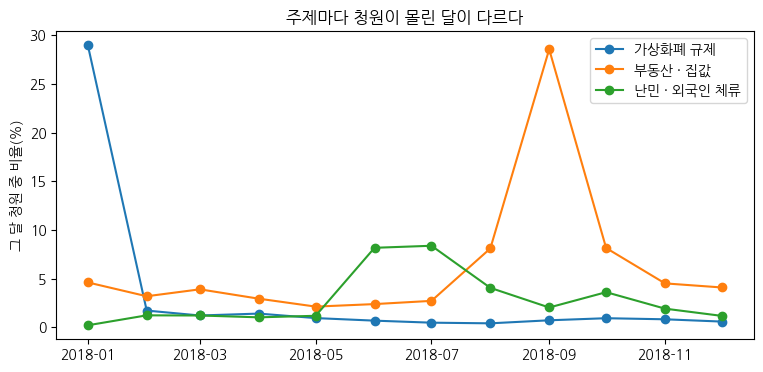

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
for name in ["가상화폐 규제", "부동산 · 집값", "난민 · 외국인 체류"]:
    t = topic_id(name)
    if t is not None and t in share.columns:
        ax.plot(share.index, share[t] * 100, marker="o", label=name)
ax.set_ylabel("그 달 청원 중 비율(%)")
ax.set_title("주제마다 청원이 몰린 달이 다르다")
ax.legend()
plt.show()

가로축은 2018년 1～12월이고, 세로축은 그 달 청원 가운데 그 토픽의 비율(%)입니다.

세 토픽은 비율이 가장 높은 달이 서로 다르고, 모두 그해의 사건과 시기가 맞습니다.

| 토픽 | 가장 높은 달 | 같은 시기의 사건 |
|---|---|---|
| 가상화폐 규제 | 2018년 1월 | 법무부 장관의 거래소 폐쇄 법안 발언(1월 11일) |
| 부동산 · 집값 | 2018년 9월 | 9 · 13 부동산 대책 |
| 난민 · 외국인 체류 | 2018년 6～7월 | 제주 예멘 난민 신청 논란 |

가상화폐 규제는 1월에 그 달 청원의 약 29%였습니다. 연평균의 약 9배입니다. 사건이 있는 달에는 한 주제의 청원이 몇 배로 늘어납니다. 정책 발표처럼 일정을 미리 알 수 있는 주제는 그 일정에 맞춰 인력을 옮깁니다.

<details><summary>더 깊이: 토픽별 비율이 가장 높은 달</summary>

| 토픽 | 가장 높은 달 | 연평균 대비 배율 | 같은 시기의 사건 |
|---|---|---:|---|
| 전기요금 누진제 | 2018년 8월 | 약 7배 | 여름 폭염 |
| 대한항공 일가 갑질 | 2018년 4월 | 약 6배 | 대한항공 일가의 갑질 보도 |
| 사법부 · 판결 | 2018년 2월 | 약 5배 | 삼성 부회장 항소심 집행유예 판결 |
| 연금 · 사회보험 | 2018년 8월 | 약 5배 | 국민연금 개편안 발표 |

배율은 「그 달 비율 ÷ 12개월 비율의 평균」입니다. 표본이 달마다 약 700～1,000건이라, 작은 토픽의 배율은 몇 건 차이로도 크게 바뀝니다.

</details>

### 우선순위 표

답변 인력을 먼저 배정할 주제를 고르는 기준은 세 가지입니다.

| 기준 | 계산 | 왜 보나 | 충족 조건 | 조건의 근거 |
|---|---|---|---|---|
| 규모 | 토픽 비율(분모 = 표본 전체) | 청원이 많으면 읽고 분류할 일이 많음 | 상위 10개 | 토픽 27개의 약 3분의 1 |
| 관심 | 동의 100 이상인 청원 비율 | 동의가 많은 청원일수록 답변 요구가 큼 | 표본 전체 평균보다 높음 | 평균이 주제와 관계없는 기준선 |
| 최근 증가 | 10～12월 비율 ÷ 1～9월 비율 | 다음 분기에도 이어질 수 있는 흐름 | 1.2배 이상 | 큰 토픽에서 우연한 변동(약 ±17%)을 넘는 크기 |

동의 수는 100 을 기준으로 씁니다. 청와대가 공식 답변하는 20만 동의 청원은 표본 1만 건에 한 건도 없어, 토픽마다 비율을 계산할 수 없습니다. 동의 100 이상은 전체의 약 6%라서, 관심이 많은 청원을 나타내면서도 토픽마다 비율을 계산할 수 있습니다.

1.2배 기준은 작은 토픽에서는 우연한 변동과 구분하기 어렵습니다. 10～12월 표본은 약 2,300건입니다. 이 크기에서는 비율이 6%인 토픽도 우연만으로 약 ±17% 달라질 수 있습니다. 비율이 2%인 토픽은 약 ±29%까지 달라집니다. 작은 토픽은 우연만으로도 1.2배를 넘을 수 있으므로, 늘어난 토픽은 원문으로 다시 확인합니다.

세 기준을 만족하는 개수가 많은 토픽부터 정렬합니다. 같으면 비율이 큰 토픽이 먼저입니다.

In [ ]:
recent = sample["begin"].dt.month >= 10
avg_agree = (sample["num_agree"] >= 100).mean() * 100

pri = topic_table().drop("이상치", errors="ignore")
pri["최근 3개월 %"] = sample[recent]["topic"].map(labels).value_counts(normalize=True) * 100
pri["앞 9개월 %"] = sample[~recent]["topic"].map(labels).value_counts(normalize=True) * 100
pri["증가 배율"] = pri["최근 3개월 %"] / pri["앞 9개월 %"]

pri["규모"] = pri["비율 %"].rank(ascending=False) <= 10
pri["관심"] = pri["동의 100 이상 %"] > avg_agree
pri["최근 증가"] = pri["증가 배율"] >= 1.2
pri["충족 수"] = pri[["규모", "관심", "최근 증가"]].sum(axis=1)
print(f"표본 전체의 동의 100 이상 비율: {avg_agree:.1f}%")
pri.sort_values(["충족 수", "비율 %"], ascending=False).round(2).head(10)

표본 전체의 동의 100 이상 비율: 5.6%


,청원 수,비율 %,동의 100 이상 %,최근 3개월 %,앞 9개월 %,증가 배율,규모,관심,최근 증가,충족 수
토픽 이름,,,,,,,,,,
범죄 처벌 강화,693,6.9,10.0,9.66,6.12,1.58,True,True,True,3
교통 · 도로 · 택시,362,3.6,5.2,6.15,2.87,2.14,True,False,True,2
난민 · 외국인 체류,292,2.9,7.5,2.33,3.09,0.75,True,True,False,2
국회 · 국회의원,287,2.9,6.6,2.81,2.89,0.97,True,True,False,2
출산 · 보육,250,2.5,9.2,3.91,2.08,1.87,False,True,True,2
공매도 · 주식시장,138,1.4,6.5,1.93,1.22,1.59,False,True,True,2
부동산 · 집값,635,6.4,2.4,5.75,6.53,0.88,True,False,False,1
남북 관계 · 북한,589,5.9,2.0,5.31,6.06,0.88,True,False,False,1
최저임금 · 근로 조건,559,5.6,2.0,5.53,5.61,0.99,True,False,False,1


세 기준을 모두 만족하는 토픽은 **범죄 처벌 강화** 하나입니다. 비율이 가장 크고, 동의 100 이상 비율이 평균의 약 1.7배이며, 최근 3개월에 약 1.5배로 늘었습니다.

두 기준을 만족하는 토픽은 5개입니다.

| 토픽 | 만족한 기준 |
|---|---|
| 교통 · 도로 · 택시 | 규모 · 최근 증가(약 2.2배) |
| 국회 · 국회의원 | 규모 · 관심 |
| 난민 · 외국인 체류 | 규모 · 관심 |
| 출산 · 보육 | 관심 · 최근 증가(약 1.9배) |
| 공매도 · 주식시장 | 관심 · 최근 증가(약 1.6배) |

합치기 전 토픽으로 계산해도 1순위는 범죄 처벌 요구로 같습니다. 합치기 전에는 출산 · 보육 대신 어린이집 · 유치원(약 3.1배 증가)이 두 기준을 만족합니다. 출산 · 보육의 증가는 대부분 어린이집 · 유치원 청원에서 왔습니다.

### 늘어난 이유 확인하기

최근 증가를 만족한 토픽이 왜 늘었는지는 드릴다운으로 확인합니다. **드릴다운(drill-down)** 은 비율이 늘어난 기간의 원문으로 내려가 무엇이 늘었는지 확인하는 일입니다. 먼저 범죄 처벌 강화 토픽의 10～12월 청원을 무작위로 읽어 봅니다.

In [ ]:
t = topic_id("범죄 처벌 강화")
if t is not None:
    recent_docs = sample[(sample["topic"] == t) & recent]
    print(f"범죄 처벌 강화 토픽의 10～12월 청원 {len(recent_docs)}건 가운데 8건")
    print("\n".join(recent_docs["doc"].sample(8, random_state=0).map(lambda d: mask(d, 60))))

범죄 처벌 강화 토픽의 10～12월 청원 220건 가운데 8건
70대 경비원 할아버지를 때린 10대청소년들 처벌해주시고,청소년법 폐지합시다. 아니 아에 범죄와의전쟁 다시 …
강서구 피씨방 사건 꼭 처벌해주세요 심신미약이라고 음주중이였다고 사건을 저지를 피의자를 감형하거나 하면 절대…
청소년 소년법 폐지해 주세요 안녕하세요. 현재 중학교를 다니고 있는 한 여학생입니다. 저는 개인적인 생각으로…
술 취한 여성 안심 귀가 서비스를 국가에서 제공해주세요. sns 나 온라인 커뮤니티에 이슈로 올라온 사진에 …
강서구 피시방 동생도 엄중 처벌 요합니다. 동생이 죽기살기로 말렸다면 그리고 피해자도 건장한 청년인데 그런 …
폐지줍던 50대여성 무차별 폭행살해한 20대 사형시켜주세요 경남 거제에서 20대 남성이 길에서 폐지를 줍던 …
이 나라는 어째 법이 범죄자를 보호하고 있는것 같다? 음준운전자 처벌 강화도 이미 수년전부터 계속 시사고발프…
사형법만 존재하는것이아닌 사형집행바랍니다 안녕하십니까 대한민국 국민5000만명중 한사람으로써 정부에게 부탁합…


아래 단어는 세 토픽의 10～12월 청원을 이렇게 읽고, 자주 나온 단어를 고른 것입니다. 그 단어가 있는 청원의 비율을 앞 9개월과 비교합니다.

In [ ]:
rows = []
for name, word in [("범죄 처벌 강화", "심신"), ("범죄 처벌 강화", "음주"),
                   ("교통 · 도로 · 택시", "카풀"), ("출산 · 보육", "사립")]:
    sub = sample[sample["topic"].map(labels) == name]
    if len(sub) == 0:
        print(f"이 실행에서는 「{name}」 토픽이 나오지 않아 건너뜁니다.")
        continue
    rows.append({"토픽": name, "단어": word,
                 "앞 9개월 %": sub.loc[~recent[sub.index], "doc"].str.contains(word).mean() * 100,
                 "최근 3개월 %": sub.loc[recent[sub.index], "doc"].str.contains(word).mean() * 100})
pd.DataFrame(rows).round(0)

,토픽,단어,앞 9개월 %,최근 3개월 %
0,범죄 처벌 강화,심신,3.0,19.0
1,범죄 처벌 강화,음주,8.0,16.0
2,교통 · 도로 · 택시,카풀,0.0,19.0
3,출산 · 보육,사립,0.0,24.0


네 단어 모두 최근 3개월에 2배 넘게 늘었습니다. 시기도 사건과 맞습니다.

- 범죄 처벌 강화: 「심신미약 감형 반대」 청원(10월 강서구 PC방 살인 사건)과 음주 운전 처벌 강화 청원(윤창호 사건)
- 교통 · 도로 · 택시: 카풀 서비스를 둘러싼 택시 업계 반발(10～12월)
- 출산 · 보육: 사립유치원 비리 공개(10월)

세 토픽의 증가는 모두 특정 사건에서 왔으므로, 최근 증가만으로 다음 분기 인력을 정하지 않습니다. 그 사건이 다음 분기에도 이어지는지 먼저 확인합니다.

- 이어지면(법 개정 논의 · 제도 개편이 진행 중이면) 다음 분기에도 인력을 먼저 배정합니다.
- 이어지지 않으면 늘어난 인력을 원래 주제로 옮기고, 부동산처럼 일정에 맞춰 옮기는 주제로 다룹니다.

## 13. 결과 정리

**핵심 질문**: 답변 담당 부서가 다음 분기에 답변 인력을 먼저 배정할 주제는 무엇일까요?

1. **범죄 처벌 강화** 에 먼저 배정합니다. 청원의 약 7%로 가장 크고, 동의 100 이상 비율이 평균의 약 1.7배입니다. 10～12월의 증가(약 1.5배)는 두 사건에서 왔지만, 이 증가가 이어지지 않아도 규모와 관심만으로 순위가 가장 높습니다.
2. 그다음은 최근 크게 늘어난 **교통 · 도로 · 택시** 와 **출산 · 보육** 입니다. 각각 약 2.2배(카풀 논쟁), 약 1.9배(사립유치원 비리)로 늘었습니다. 두 사건이 다음 분기에도 이어지는지 확인하고 배정합니다.
3. **국회 · 국회의원**, **난민 · 외국인 체류** 는 동의가 많이 모이지만 최근 늘지는 않았습니다. 지금 인력을 유지합니다.
4. 비율이 큰 **부동산 · 집값**, **남북 관계 · 북한** 은 동의 100 이상 비율이 평균보다 낮고 최근 줄었습니다. 다만 부동산은 9월 대책 발표 직후에 그 달 청원의 약 29%로 몰렸습니다. 그래서 대책 발표 일정에 맞춰 인력을 늘립니다.
5. **인터넷 게시판 · 댓글** 은 우선순위 상위는 아니지만, 게시판 운영 요구가 많아 이 부서가 직접 답합니다.

**한계**

- 다음 분기를 예측한 결과가 아닙니다. 2018년 10～12월의 증가가 다음 분기에도 이어진다고 가정합니다.
- 청원의 약 3분의 1은 이상치입니다. 이상치 안에 아직 토픽이 되지 못한 작은 새 주제가 있을 수 있습니다.
- 토픽은 청원마다 하나입니다. 주제가 2개인 청원은 한 주제로만 집계됩니다.

## 14. 새 청원에 토픽 배정하기

결과 정리를 마친 뒤에도 청원은 계속 들어옵니다. 새 청원이 들어올 때마다 다시 학습하지 않으려면, 학습한 모델로 새 청원에 토픽을 배정합니다. 학습에 쓰지 않은 청원 500건으로 해 봅니다.

### 학습한 모델로 배정하기

`transform` 은 학습한 모델로 새 청원의 토픽을 정합니다. 학습한 모델(`topic_model`)은 아래 순서로 정합니다.

1. 새 청원의 임베딩을 학습 때의 UMAP 으로 5차원으로 줄입니다.
2. HDBSCAN 이 학습 때 만든 군집 가운데 가까운 군집을 고릅니다.
3. 밀도가 낮은 곳이라 어느 군집에도 속하지 않으면 −1 입니다.

배정 비율이 학습 표본과 비슷하면, 새 청원도 학습 때와 같은 기준으로 배정된다고 볼 수 있습니다.

In [ ]:
new_topics, _ = topic_model.transform(new["nouns"].tolist(), embeddings=emb_new)
new["topic"] = new_topics

train_share = sample["topic"].map(labels).value_counts(normalize=True) * 100
def gap(topics):
    # 총변동 거리: 토픽마다 비율 차이의 절댓값을 더해 2로 나눈 값(%p)
    s = pd.Series(topics).map(labels).value_counts(normalize=True) * 100
    return train_share.sub(s, fill_value=0).abs().sum() / 2

print(f"총변동 거리, 학습 표본 대 새 청원 500건: {gap(new_topics):.1f}%p")
base_gaps = [gap(sample["topic"].sample(500, random_state=i)) for i in range(20)]
print(f"총변동 거리, 학습 표본 대 다시 추출한 500건(20번): 평균 {np.mean(base_gaps):.1f}%p, "
      f"범위 {min(base_gaps):.1f}～{max(base_gaps):.1f}%p")

cmp = pd.DataFrame({"학습 표본 %": train_share,
                    "새 청원 %": new["topic"].map(labels).value_counts(normalize=True) * 100}).fillna(0)
cmp.sort_values("학습 표본 %", ascending=False).round(1).head(8)

총변동 거리, 학습 표본 대 새 청원 500건: 8.1%p
총변동 거리, 학습 표본 대 다시 추출한 500건(20번): 평균 8.0%p, 범위 5.9～11.9%p


,학습 표본 %,새 청원 %
topic,,
이상치,31.5,33.6
범죄 처벌 강화,6.9,6.8
부동산 · 집값,6.4,4.2
남북 관계 · 북한,5.9,7.0
최저임금 · 근로 조건,5.6,6.0
인터넷 게시판 · 댓글,3.8,4.2
가상화폐 규제,3.6,3.8
교통 · 도로 · 택시,3.6,3.4


**총변동 거리(total variation distance)** 는 두 비율표가 얼마나 다른지 나타내는 값입니다. 새 청원 가운데 몇 %를 다른 토픽으로 옮겨야 학습 표본과 같아지는지를 계산합니다. 두 비율표가 같으면 0 입니다. 새 청원 500건의 총변동 거리는 약 8～9%p 입니다.

이 값이 큰지 작은지 알려면 비교 기준이 필요합니다. 학습 표본에서 500건을 다시 추출해 같은 값을 20번 계산하면 그 기준이 됩니다. 같은 청원에서 추출해도 500건이면 총변동 거리가 평균 약 8%p, 20번 가운데 약 6～11%p 입니다.

새 청원의 약 8～9%p 는 이 범위 안에 있습니다. 학습 표본과 같은 2018년 청원이라, 우연 수준의 차이만 있는 것이 정상입니다. 다른 해의 청원에서 총변동 거리가 이 범위보다 크면 새 주제가 생겼을 수 있습니다.

<details><summary>더 깊이: 총변동 거리의 계산</summary>

총변동 거리는 토픽마다 비율 차이의 절댓값을 더해 2로 나눈 값입니다. 토픽 A · B 두 개만 있고 학습 표본이 60% · 40%, 새 청원이 50% · 50%라고 해 봅니다. 차이의 절댓값은 A 에서 10, B 에서 10 이고, 합은 20 입니다. 그런데 새 청원 가운데 B 로 간 10%를 A 로 옮기면 두 표가 같아집니다. 옮긴 10%가 A 에서 한 번, B 에서 한 번 계산됐으므로, 옮겨야 하는 양은 합의 절반인 10%p 입니다.

</details>

### 모델 저장

학습한 모델을 저장해 두면, 런타임이 끝난 뒤에도 다시 학습하지 않고 새 청원을 배정할 수 있습니다. `save` 의 인자는 모두 직접 지정합니다.

| 형식 | 저장하는 것 | 장점 | 단점 |
|---|---|---|---|
| safetensors | 수 배열(토픽 임베딩 · c-TF-IDF)과 설정 | 불러올 때 코드가 실행되지 않아 안전하고, 파일이 작음 | 수 배열로 저장할 수 없는 UMAP · HDBSCAN 은 빠짐 |
| pickle | 파이썬 객체 전체(UMAP · HDBSCAN 포함) | 학습한 모델과 똑같이 배정 | 불러올 때 임의 코드가 실행될 수 있고, 파일이 큼 |

- `serialization="safetensors"`: BERTopic 문서가 권하는 형식입니다. 코드의 기본값은 `"pickle"` 이라 직접 지정합니다.
- `save_ctfidf=True`: 토픽 단어 계산에 쓴 c-TF-IDF 와 단어 목록을 함께 저장합니다.
- `save_embedding_model`: 임베딩 모델 자체가 아니라 이름만 저장합니다. 불러올 때 이 이름으로 모델을 다시 내려받습니다.

In [ ]:
SAVE_DIR = "petition_topic_model"
topic_model.save(SAVE_DIR, serialization="safetensors", save_ctfidf=True,
                 save_embedding_model="nlpai-lab/KURE-v1")
size_kb = sum(os.path.getsize(os.path.join(SAVE_DIR, f)) for f in os.listdir(SAVE_DIR)) / 1024
print(f"저장한 파일: {sorted(os.listdir(SAVE_DIR))}, 합계 {size_kb:.0f}KB")

저장한 파일: ['config.json', 'ctfidf.safetensors', 'ctfidf_config.json', 'topic_embeddings.safetensors', 'topics.json'], 합계 1528KB


### 불러온 모델의 토픽 배정 방식

safetensors 로 저장한 모델에는 UMAP · HDBSCAN 이 없습니다. 그래서 불러온 모델은 토픽 임베딩으로 토픽을 정합니다.

- **토픽 임베딩** 은 토픽마다 그 토픽에 속한 청원 임베딩의 평균입니다. 이상치(−1)도 이상치 청원 임베딩의 평균을 하나 가집니다.
- 새 청원의 임베딩과 코사인 유사도가 가장 큰 토픽 임베딩을 고릅니다.
- 가장 가까운 것이 이상치의 평균이면 −1 입니다.

학습한 모델과 방식이 다르므로, 같은 500건의 결과도 달라집니다.

In [ ]:
loaded = BERTopic.load(SAVE_DIR, embedding_model=emb_model)
loaded_topics, _ = loaded.transform(new["nouns"].tolist(), embeddings=emb_new)
loaded_topics = np.array(loaded_topics)

print(f"학습한 모델의 이상치: {np.mean(np.array(new_topics) == -1):.1%}")
print(f"불러온 모델의 이상치: {np.mean(loaded_topics == -1):.1%}")
inside = np.array(new_topics) != -1
print(f"학습한 모델이 토픽을 정한 청원 중 같은 토픽: {np.mean(loaded_topics[inside] == np.array(new_topics)[inside]):.1%}")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

학습한 모델의 이상치: 33.6%
불러온 모델의 이상치: 8.4%
학습한 모델이 토픽을 정한 청원 중 같은 토픽: 90.1%


학습한 모델은 새 청원의 약 34～36%를 이상치로 남겼고, 불러온 모델은 약 8%만 남겼습니다. 이상치의 평균은 여러 주제 청원의 평균이라, 새 청원 대부분은 그보다 가까운 토픽 임베딩이 있기 때문입니다. 학습한 모델이 토픽을 정한 청원은 약 90%가 불러온 모델에서도 같은 토픽입니다.

그래도 safetensors 로 저장하는 이유는, 남에게 받은 모델 파일을 불러올 때 코드가 실행되지 않아 안전하기 때문입니다. 학습한 모델과 똑같이 배정해야 하고 파일을 만든 사람을 믿을 수 있을 때만 pickle 로 저장합니다.

어느 쪽이든 새 청원의 비율을 학습 표본과 비교할 때는 기준을 맞춥니다. 운영에서 불러온 모델을 쓴다면, 학습 표본도 불러온 모델로 다시 배정해 비교 기준을 만듭니다.

### 설정 기록

결과를 다시 만들려면 아래 설정이 모두 필요합니다.

In [ ]:
settings = {
    "데이터": "heegyu/korean-petitions, 2018-01～12 시작 청원",
    "정제": f"본문 빈 청원 · 제목과 본문이 같은 중복 청원 제외, 제목 + 본문 {MAX_LEN}자",
    "표본": f"{len(sample):,}건(random_state=0), 새 청원 {len(new)}건(random_state=1)",
    "임베딩 모델": "nlpai-lab/KURE-v1, normalize, max_seq_length 256",
    "임베딩 계산 장치": f"{device}" + (", 16비트(half)" if device == "cuda" else ", 32비트"),
    "UMAP": f"{umap_args}, random_state=0",
    "HDBSCAN": "min_cluster_size=50, euclidean, eom",
    "토픽 단어": f"Kiwi NNG · NNP, 사용자 사전 2개, 불용어 {len(STOP_WORDS)}개",
    "합치기": " / ".join(" + ".join(p) for p in merge_plan.values()),
    "이상치": "결과 정리는 재배정 전 비율, 재배정(c-tf-idf, 0.1)은 topic_re 열",
    "버전": f"bertopic {bertopic.__version__}",
}
pd.Series(settings, name="값").to_frame()

,값
데이터,"heegyu/korean-petitions, 2018-01～12 시작 청원"
정제,"본문 빈 청원 · 제목과 본문이 같은 중복 청원 제외, 제목 + 본문 150자"
표본,"10,000건(random_state=0), 새 청원 500건(random_state=1)"
임베딩 모델,"nlpai-lab/KURE-v1, normalize, max_seq_length 256"
임베딩 계산 장치,"cuda, 16비트(half)"
UMAP,"{'n_neighbors': 15, 'n_components': 5, 'min_dist': 0.0, 'metric': 'cosine'}, random_st..."
HDBSCAN,"min_cluster_size=50, euclidean, eom"
토픽 단어,"Kiwi NNG · NNP, 사용자 사전 2개, 불용어 23개"
합치기,양육비 · 출산 지원 + 어린이집 · 유치원 / 범죄 처벌 요구 + 음주 운전 처벌 / 청원 게시판 운영 + 포털 댓글 · 언론
이상치,"결과 정리는 재배정 전 비율, 재배정(c-tf-idf, 0.1)은 topic_re 열"


## 15. 직접 해 보기

아래 빈 셀에 코드를 써서 실행해 봅니다. 위 셀의 코드를 복사해 고쳐 써도 됩니다. 「답 확인」에는 Apple M1 맥에서 실행한 예시 답이 있습니다.

**1. 최소 군집 크기 바꾸기**

「6. 최소 군집 크기 고르기」의 표에 40 과 70 을 추가합니다. 값을 30 → 40 → 50 → 70 → 100 으로 키울 때, 토픽 수가 한 방향으로 줄어드나요? 갑자기 크게 줄어드는 곳이 있나요?

<details><summary>답 확인</summary>

토픽 수는 약 56 → 35 → 31 → 26 → 21개로 한 방향으로 줄어듭니다(시드 0 · 1 · 2 의 평균). 30 에서 40 사이에서 가장 크게 줄고, 그 뒤로는 고르게 줄어듭니다. 이상치는 약 29～36%이고, 가장 큰 토픽은 모든 값에서 8% 이하입니다. 이 데이터에서는 뉴스 기사 제목 데이터처럼 토픽이 갑자기 몇 개로 줄어드는 값이 없습니다.

</details>

**2. 재배정 방법 바꾸기**

`embeddings` 방법은 이상치 청원의 임베딩과 토픽 임베딩(토픽에 속한 청원 임베딩의 평균)의 코사인 유사도로 재배정합니다. `strategy="embeddings"` 로 재배정합니다. 이때 `embeddings=emb` 도 지정합니다. `threshold` 는 0.3 · 0.5 · 0.7 로 바꿔 봅니다. 남은 이상치 비율이 어떻게 바뀌나요? c-TF-IDF 방법의 0.1 과 같은 뜻인가요?

<details><summary>답 확인</summary>

남은 이상치는 `threshold` 0.3 에서 0%, 0.5 에서 약 0.2%, 0.7 에서 약 28%입니다. 이상치 청원 대부분이 어떤 토픽 임베딩과는 코사인 유사도가 0.5 이상이기 때문입니다. `threshold` 의 숫자는 방법마다 뜻이 달라서, c-TF-IDF 방법의 0.1 과 같은 값으로 비교할 수 없습니다.

</details>

**3. 다음 해 청원 배정하기**

2019년 1월 청원 500건을 읽어 `transform` 으로 배정합니다. 2018년 표본과 비교해 비율이 크게 다른 토픽은 무엇인가요? 이상치 비율이 늘었다면 새 주제가 생겼을 수 있습니다. 이상치 청원을 읽어 확인합니다.

<details><summary>답 확인</summary>

2019년 1월 청원 약 2만 건에서 500건을 무작위로 추출하면, 이상치가 약 38%로 학습 표본(약 32%)보다 많습니다. 총변동 거리는 약 15%p 로, 같은 2018년 청원의 범위(약 6～11%p)보다 큽니다.

- 크게 늘어난 토픽: 미세먼지(약 1.6% → 6.4%), 국회 · 국회의원(약 3.1% → 5.8%)
- 크게 줄어든 토픽: 가상화폐 규제 · 난민 · 외국인 체류(각각 1% 아래)
- 이상치 청원에 많은 단어: 「예천」(군의회 해외연수 논란), 「그랜드캐년」(관광객 추락 사고), 현직 국회의원의 부동산 투기 의혹

2018년 토픽에 없는 2019년 1월의 새 사건이 이상치로 모였습니다. 이런 이상치를 모아 주기적으로 다시 토픽 모델링하면 새 주제를 찾을 수 있습니다.

</details>

In [ ]:
# 1. 최소 군집 크기 바꾸기
# 힌트: HDBSCAN(min_cluster_size=40).fit(reduced[0]).labels_ 를 summary(...) 로 요약

In [ ]:
# 2. 재배정 방법 바꾸기
# 힌트: topic_model.reduce_outliers(docs_nouns, topic_model.topics_,
#    strategy="embeddings", embeddings=emb, threshold=0.5)

In [ ]:
# 3. 다음 해 청원 배정하기
# 힌트: 위 BASE 의 1.parquet 에서 begin 이 2019-01 인 행을 읽고,
#    doc · nouns 를 만든 뒤 emb_model.encode 와 topic_model.transform 을 차례로 실행

## 정리

- 토픽 모델링을 시작하기 전에 결과를 받는 사람과 그 사람이 내릴 결정부터 정합니다. 토픽 수와 합치기 수준은 그 결정에 맞춥니다.
- 임베딩은 한 번 계산해 저장하고, 설정을 바꿀 때는 저장한 임베딩을 다시 씁니다.
- 한국어는 `language="multilingual"` 과 Kiwi 명사로 토픽 단어를 만듭니다. 불용어는 임베딩이 아니라 단어 집계에서 뺍니다.
- 최소 군집 크기는 토픽 수 · 이상치 비율 · 가장 큰 토픽 비율을 함께 보고 고릅니다. 시드를 고정하면 결과를 다시 만들 수 있고, 결과가 안정적인지는 시드를 바꿔 실행해 확인합니다.
- 토픽 이름은 대표 · 무작위 · 경계 청원을 읽고, 반대 입장의 청원도 있는지 본 뒤 정합니다.
- 비율의 분모는 이상치를 포함한 전체입니다. 재배정은 비율을 바꾸므로 재배정 전 비율을 씁니다.
- 최근 증가한 주제는 원문으로 원인을 확인하고, 그 원인이 이어지는지 본 뒤 인력을 배정합니다.
- 저장은 safetensors 로 하고, 새 청원의 비교 기준은 운영에서 쓸 배정 방식으로 다시 계산합니다.

## 참고 자료

**BERTopic 공식 문서**

- [Best Practices](https://maartengr.github.io/BERTopic/getting_started/best_practices/best_practices.html): 임베딩 미리 계산 · 시드 고정 · 최소 군집 크기 · safetensors 저장
- [Outlier reduction](https://maartengr.github.io/BERTopic/getting_started/outlier_reduction/outlier_reduction.html): `reduce_outliers` 의 4가지 방법
- [Hierarchical topic modeling](https://maartengr.github.io/BERTopic/getting_started/hierarchicaltopics/hierarchicaltopics.html) · [Topic reduction](https://maartengr.github.io/BERTopic/getting_started/topicreduction/topicreduction.html): 계층 토픽과 합치기
- [Topics over time](https://maartengr.github.io/BERTopic/getting_started/topicsovertime/topicsovertime.html): 기간별 토픽
- [Representation models](https://maartengr.github.io/BERTopic/getting_started/representation/representation.html): KeyBERTInspired · MMR
- [Vectorizers](https://maartengr.github.io/BERTopic/getting_started/vectorizers/vectorizers.html) · [FAQ](https://maartengr.github.io/BERTopic/faq.html): 토크나이저 · 불용어 · 이상치
- [Serialization](https://maartengr.github.io/BERTopic/getting_started/serialization/serialization.html): 저장 형식 비교
- [Use cases](https://maartengr.github.io/BERTopic/usecases.html): 기업 · 기관 사례 모음

**논문**

- Grootendorst (2022), [BERTopic: Neural topic modeling with a class-based TF-IDF procedure](https://arxiv.org/abs/2203.05794)
- McInnes · Healy · Melville (2018), [UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction](https://arxiv.org/abs/1802.03426)
- Campello · Moulavi · Sander (2013), [Density-Based Clustering Based on Hierarchical Density Estimates](https://doi.org/10.1007/978-3-642-37456-2_14)
- Hoyle 외 (2021), [Is Automated Topic Model Evaluation Broken? The Incoherence of Coherence](https://arxiv.org/abs/2107.02173)
- Chang 외 (2009), [Reading Tea Leaves: How Humans Interpret Topic Models](https://papers.nips.cc/paper/2009/hash/f92586a25bb3145facd64ab20fd554ff-Abstract.html)
- Greene 외 (2014), [How Many Topics? Stability Analysis for Topic Models](https://arxiv.org/abs/1404.4606)

**사례**

- Bašaragin 외 (2025), [Improving Customer Service with Automatic Topic Detection in User Emails](https://arxiv.org/abs/2502.19115): Telekom Srbija 사례(토픽 72개 → 업무 분류 12개)
- Mansurova (2023), [Topic Modelling in production](https://towardsdatascience.com/topic-modelling-in-production-e3b3e99e4fca/): 호텔 리뷰 토픽 배정 서비스와 새 토픽 감시

**라이브러리 · 모델 · 데이터**

- [kiwipiepy](https://github.com/bab2min/kiwipiepy) · [KURE-v1](https://huggingface.co/nlpai-lab/KURE-v1) · [heegyu/korean-petitions](https://huggingface.co/datasets/heegyu/korean-petitions)